In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import scipy
from scipy.stats import ttest_ind
import seaborn as sns
from math import sqrt
import re
from matplotlib.ticker import ScalarFormatter
import matplotlib.ticker as mticker
from itertools import product

cell_types = ["Exc", "Pvalb", "Sst", "Vip", "Htr3a"]
layers = ["L1", "L2/3", "L4", "L5", "L6"]

In [2]:
power_orig_net = pd.read_csv("core/metrics/dg_L4L6model_silencing_power/dg_all_dirs_mua_power_layer.csv")
# power_L4_w_L6_cell_dens = pd.read_csv(
#     "core_L4-cell-density-as-L6/metrics/dg_layer_silencing_power/dg_all_dirs_mua_power_layer.csv"
# )
power_L4_w_L6_cell_vol_dens = pd.read_csv(
    "core_L4-cell-volume-density-as-L6/metrics/dg_layer_silencing_power/dg_all_dirs_mua_power_layer.csv"
)
power_L4_w_L6_conn = pd.read_csv(
    "core_L4-connectivity-as-L6/metrics/dg_layer_silencing_power/dg_all_dirs_mua_power_layer.csv"
)
power_L4_w_L6_cell_vol_dens_conn = pd.read_csv(
    "core_L4-cell-vol-dens-conn-as-L6/metrics/dg_layer_silencing_power/dg_all_dirs_mua_power_layer.csv"
)
power_L4_w_L6_syn = pd.read_csv(
    "core_L4-syn-as-L6-syn/metrics/dg_layer_silencing_power/dg_all_dirs_mua_power_layer.csv"
)
# power_L4_w_L6_syn_PSP = pd.read_csv(
#     "core_L4-syn-PSP-as_L6/metrics/dg_layer_silencing_power/dg_all_dirs_mua_power_layer.csv"
# )


power_L4_e2e_syn_as_L6 = pd.read_csv(
    "core_L4-e2e-syn-as-L6/metrics/dg_layer_silencing_power/dg_all_dirs_mua_power_layer.csv"
)
power_L4_e2i_syn_as_L6 = pd.read_csv(
    "core_L4-e2i-syn-as-L6/metrics/dg_layer_silencing_power/dg_all_dirs_mua_power_layer.csv"
)
power_L4_i2e_syn_as_L6 = pd.read_csv(
    "core_L4-i2e-syn-as-L6/metrics/dg_layer_silencing_power/dg_all_dirs_mua_power_layer.csv"
)


power_L4_Pvalb2e_syn_as_L6 = pd.read_csv(
    "core_L4-Pvalb2e-as-L6/metrics/dg_layer_silencing_power/dg_all_dirs_mua_power_layer.csv"
)
power_L4_Pvalb2e_syn_lat_as_L6 = pd.read_csv(
    "core_L4-Pvalb2e-syn-lat-as-L6/metrics/dg_layer_silencing_power/dg_all_dirs_mua_power_layer.csv"
)
power_L4_Pvalb2e_syn_tau_amp_as_L6 = pd.read_csv(
    "core_L4-Pvalb2e-syn-tau-amp-as-L6/metrics/dg_layer_silencing_power/dg_all_dirs_mua_power_layer.csv"
)


power_L4_Sst2e_syn_as_L6 = pd.read_csv(
    "core_L4-Sst2e-as-L6/metrics/dg_layer_silencing_power/dg_all_dirs_mua_power_layer.csv"
)
power_L4_Sst2e_syn_lat_as_L6 = pd.read_csv(
    "core_L4-Sst2e-syn-lat-as-L6/metrics/dg_layer_silencing_power/dg_all_dirs_mua_power_layer.csv"
)
power_L4_Sst2e_syn_tau_amp_as_L6 = pd.read_csv(
    "core_L4-Sst2e-syn-tau-amp-as-L6/metrics/dg_layer_silencing_power/dg_all_dirs_mua_power_layer.csv"
)


power_L4_Vip2e_syn_lat_as_L6 = pd.read_csv(
    "core_L4-Vip2e-syn-lat-as-L6/metrics/dg_layer_silencing_power/dg_all_dirs_mua_power_layer.csv"
)
power_L4_Vip2e_syn_tau_amp_as_L6 = pd.read_csv(
    "core_L4-Vip2e-syn-tau-amp-as-L6/metrics/dg_layer_silencing_power/dg_all_dirs_mua_power_layer.csv"
)

In [3]:
# L6 as L4
power_L6_w_L4_syn = pd.read_csv(
    "core_L6-syn-as-L4-syn/metrics/dg_layer_silencing_power/dg_all_dirs_mua_power_layer.csv"
)
power_L6_as_L4 = pd.read_csv(
    "core_L6-as-L4/metrics/dg_layer_silencing_power/dg_all_dirs_mua_power_layer.csv"
)

In [4]:
power_L6_as_L4.condition.unique()

array(['L4 models', 'L4 models: L6', 'L6', 'no perturb'], dtype=object)

In [5]:
def str2list(str_time):
    str_time = str_time[1:-1]
    array_list = str_time.strip(",").split(", ")
    return np.stack([float(ii) for ii in array_list])

In [6]:
power_orig_net["power"] = power_orig_net["power"].apply(str2list)
power_orig_net["f"] = power_orig_net["f"].apply(str2list)

# power_L4_w_L6_cell_dens["power"] = power_L4_w_L6_cell_dens["power"].apply(str2list)
# power_L4_w_L6_cell_dens["f"] = power_L4_w_L6_cell_dens["f"].apply(str2list)

power_L4_w_L6_cell_vol_dens["power"] = power_L4_w_L6_cell_vol_dens["power"].apply(str2list)
power_L4_w_L6_cell_vol_dens["f"] = power_L4_w_L6_cell_vol_dens["f"].apply(str2list)

power_L4_w_L6_cell_vol_dens_conn["power"] = power_L4_w_L6_cell_vol_dens_conn["power"].apply(str2list)
power_L4_w_L6_cell_vol_dens_conn["f"] = power_L4_w_L6_cell_vol_dens_conn["f"].apply(str2list)

power_L4_w_L6_conn["power"] = power_L4_w_L6_conn["power"].apply(str2list)
power_L4_w_L6_conn["f"] = power_L4_w_L6_conn["f"].apply(str2list)

power_L4_w_L6_syn["power"] = power_L4_w_L6_syn["power"].apply(str2list)
power_L4_w_L6_syn["f"] = power_L4_w_L6_syn["f"].apply(str2list)

# power_L4_w_L6_syn_PSP["power"] = power_L4_w_L6_syn_PSP["power"].apply(str2list)
# power_L4_w_L6_syn_PSP["f"] = power_L4_w_L6_syn_PSP["f"].apply(str2list)

power_L4_e2e_syn_as_L6["power"] = power_L4_e2e_syn_as_L6["power"].apply(str2list)
power_L4_e2e_syn_as_L6["f"] = power_L4_e2e_syn_as_L6["f"].apply(str2list)

power_L4_e2i_syn_as_L6["power"] = power_L4_e2i_syn_as_L6["power"].apply(str2list)
power_L4_e2i_syn_as_L6["f"] = power_L4_e2i_syn_as_L6["f"].apply(str2list)

power_L4_i2e_syn_as_L6["power"] = power_L4_i2e_syn_as_L6["power"].apply(str2list)
power_L4_i2e_syn_as_L6["f"] = power_L4_i2e_syn_as_L6["f"].apply(str2list)

power_L4_Pvalb2e_syn_as_L6["power"] = power_L4_Pvalb2e_syn_as_L6["power"].apply(str2list)
power_L4_Pvalb2e_syn_as_L6["f"] = power_L4_Pvalb2e_syn_as_L6["f"].apply(str2list)
power_L4_Pvalb2e_syn_lat_as_L6["power"] = power_L4_Pvalb2e_syn_lat_as_L6["power"].apply(str2list)
power_L4_Pvalb2e_syn_lat_as_L6["f"] = power_L4_Pvalb2e_syn_lat_as_L6["f"].apply(str2list)
power_L4_Pvalb2e_syn_tau_amp_as_L6["power"] = power_L4_Pvalb2e_syn_tau_amp_as_L6["power"].apply(str2list)
power_L4_Pvalb2e_syn_tau_amp_as_L6["f"] = power_L4_Pvalb2e_syn_tau_amp_as_L6["f"].apply(str2list)

power_L4_Sst2e_syn_as_L6["power"] = power_L4_Sst2e_syn_as_L6["power"].apply(str2list)
power_L4_Sst2e_syn_as_L6["f"] = power_L4_Sst2e_syn_as_L6["f"].apply(str2list)
power_L4_Sst2e_syn_lat_as_L6["power"] = power_L4_Sst2e_syn_lat_as_L6["power"].apply(str2list)
power_L4_Sst2e_syn_lat_as_L6["f"] = power_L4_Sst2e_syn_lat_as_L6["f"].apply(str2list)
power_L4_Sst2e_syn_tau_amp_as_L6["power"] = power_L4_Sst2e_syn_tau_amp_as_L6["power"].apply(str2list)
power_L4_Sst2e_syn_tau_amp_as_L6["f"] = power_L4_Sst2e_syn_tau_amp_as_L6["f"].apply(str2list)

power_L4_Vip2e_syn_lat_as_L6["power"] = power_L4_Vip2e_syn_lat_as_L6["power"].apply(str2list)
power_L4_Vip2e_syn_lat_as_L6["f"] = power_L4_Vip2e_syn_lat_as_L6["f"].apply(str2list)
power_L4_Vip2e_syn_tau_amp_as_L6["power"] = power_L4_Vip2e_syn_tau_amp_as_L6["power"].apply(str2list)
power_L4_Vip2e_syn_tau_amp_as_L6["f"] = power_L4_Vip2e_syn_tau_amp_as_L6["f"].apply(str2list)

In [7]:
power_orig_net.condition.unique()

array(['L2/3', 'L4', 'L5', 'L6', 'L6 models', 'L6 models: L2/3',
       'L6 models: L4', 'L6 models: L5', 'L6 models: L6', 'no perturb'],
      dtype=object)

In [8]:
# L6 as L4
power_L6_w_L4_syn["power"] = power_L6_w_L4_syn["power"].apply(str2list)
power_L6_w_L4_syn["f"] = power_L6_w_L4_syn["f"].apply(str2list)

# power_L6_w_L4_syn_PSP["power"] = power_L6_w_L4_syn_PSP["power"].apply(str2list)
# power_L6_w_L4_syn_PSP["f"] = power_L6_w_L4_syn_PSP["f"].apply(str2list)

# power_L6_w_L4_syn_v2["power"] = power_L6_w_L4_syn_v2["power"].apply(str2list)
# power_L6_w_L4_syn_v2["f"] = power_L6_w_L4_syn_v2["f"].apply(str2list)

power_L6_as_L4["power"] = power_L6_as_L4["power"].apply(str2list)
power_L6_as_L4["f"] = power_L6_as_L4["f"].apply(str2list)

In [9]:
power_orig_net_df = power_orig_net.groupby(["condition", "layer"]).agg(
    {
        "power": list,
        "f": list,
    }
)
power_orig_net_df.reset_index(inplace=True)
power_orig_net_df["mean"] = power_orig_net_df["power"].apply(np.mean, axis=0)
power_orig_net_df["se"] = power_orig_net_df["power"].apply(lambda x: np.std(x, axis=0) / np.sqrt(len(x)))
power_orig_net_df["f"] = power_orig_net_df["f"].apply(np.mean, axis=0)

In [10]:
power_L4_w_L6_cell_vol_dens_df = power_L4_w_L6_cell_vol_dens.groupby(["condition", "layer"]).agg(
    {
        "power": list,
        "f": list,
    }
)
power_L4_w_L6_cell_vol_dens_df.reset_index(inplace=True)
power_L4_w_L6_cell_vol_dens_df["mean"] = power_L4_w_L6_cell_vol_dens_df["power"].apply(np.mean, axis=0)
power_L4_w_L6_cell_vol_dens_df["se"] = power_L4_w_L6_cell_vol_dens_df["power"].apply(lambda x: np.std(x, axis=0) / np.sqrt(len(x)))
power_L4_w_L6_cell_vol_dens_df["f"] = power_L4_w_L6_cell_vol_dens_df["f"].apply(np.mean, axis=0)

power_L4_w_L6_cell_vol_dens_conn_df = power_L4_w_L6_cell_vol_dens_conn.groupby(["condition", "layer"]).agg(
    {
        "power": list,
        "f": list,
    }
)
power_L4_w_L6_cell_vol_dens_conn_df.reset_index(inplace=True)
power_L4_w_L6_cell_vol_dens_conn_df["mean"] = power_L4_w_L6_cell_vol_dens_conn_df["power"].apply(np.mean, axis=0)
power_L4_w_L6_cell_vol_dens_conn_df["se"] = power_L4_w_L6_cell_vol_dens_conn_df["power"].apply(lambda x: np.std(x, axis=0) / np.sqrt(len(x)))
power_L4_w_L6_cell_vol_dens_conn_df["f"] = power_L4_w_L6_cell_vol_dens_conn_df["f"].apply(np.mean, axis=0)

In [11]:
power_L4_w_L6_conn_df = power_L4_w_L6_conn.groupby(["condition", "layer"]).agg(
    {
        "power": list,
        "f": list,
    }
)
power_L4_w_L6_conn_df.reset_index(inplace=True)
power_L4_w_L6_conn_df["mean"] = power_L4_w_L6_conn_df["power"].apply(np.mean, axis=0)
power_L4_w_L6_conn_df["se"] = power_L4_w_L6_conn_df["power"].apply(lambda x: np.std(x, axis=0) / np.sqrt(len(x)))
power_L4_w_L6_conn_df["f"] = power_L4_w_L6_conn_df["f"].apply(np.mean, axis=0)

In [12]:
power_L4_w_L6_syn_df = power_L4_w_L6_syn.groupby(["condition", "layer"]).agg(
    {
        "power": list,
        "f": list,
    }
)
power_L4_w_L6_syn_df.reset_index(inplace=True)
power_L4_w_L6_syn_df["mean"] = power_L4_w_L6_syn_df["power"].apply(np.mean, axis=0)
power_L4_w_L6_syn_df["se"] = power_L4_w_L6_syn_df["power"].apply(lambda x: np.std(x, axis=0) / np.sqrt(len(x)))
power_L4_w_L6_syn_df["f"] = power_L4_w_L6_syn_df["f"].apply(np.mean, axis=0)

# power_L4_w_L6_syn_PSP_df = power_L4_w_L6_syn_PSP.groupby(["condition", "layer"]).agg(
#     {
#         "power": list,
#         "f": list,
#     }
# )
# power_L4_w_L6_syn_PSP_df.reset_index(inplace=True)
# power_L4_w_L6_syn_PSP_df["mean"] = power_L4_w_L6_syn_PSP_df["power"].apply(np.mean, axis=0)
# power_L4_w_L6_syn_PSP_df["se"] = power_L4_w_L6_syn_PSP_df["power"].apply(lambda x: np.std(x, axis=0) / np.sqrt(len(x)))
# power_L4_w_L6_syn_PSP_df["f"] = power_L4_w_L6_syn_PSP_df["f"].apply(np.mean, axis=0)

power_L4_e2e_syn_as_L6_df = power_L4_e2e_syn_as_L6.groupby(["condition", "layer"]).agg(
    {
        "power": list,
        "f": list,
    }
)
power_L4_e2e_syn_as_L6_df.reset_index(inplace=True)
power_L4_e2e_syn_as_L6_df["mean"] = power_L4_e2e_syn_as_L6_df["power"].apply(np.mean, axis=0)
power_L4_e2e_syn_as_L6_df["se"] = power_L4_e2e_syn_as_L6_df["power"].apply(lambda x: np.std(x, axis=0) / np.sqrt(len(x)))
power_L4_e2e_syn_as_L6_df["f"] = power_L4_e2e_syn_as_L6_df["f"].apply(np.mean, axis=0)

power_L4_e2i_syn_as_L6_df = power_L4_e2i_syn_as_L6.groupby(["condition", "layer"]).agg(
    {
        "power": list,
        "f": list,
    }
)
power_L4_e2i_syn_as_L6_df.reset_index(inplace=True)
power_L4_e2i_syn_as_L6_df["mean"] = power_L4_e2i_syn_as_L6_df["power"].apply(np.mean, axis=0)
power_L4_e2i_syn_as_L6_df["se"] = power_L4_e2i_syn_as_L6_df["power"].apply(lambda x: np.std(x, axis=0) / np.sqrt(len(x)))
power_L4_e2i_syn_as_L6_df["f"] = power_L4_e2i_syn_as_L6_df["f"].apply(np.mean, axis=0)

In [13]:
power_L4_i2e_syn_as_L6_df = power_L4_i2e_syn_as_L6.groupby(["condition", "layer"]).agg(
    {
        "power": list,
        "f": list,
    }
)
power_L4_i2e_syn_as_L6_df.reset_index(inplace=True)
power_L4_i2e_syn_as_L6_df["mean"] = power_L4_i2e_syn_as_L6_df["power"].apply(np.mean, axis=0)
power_L4_i2e_syn_as_L6_df["se"] = power_L4_i2e_syn_as_L6_df["power"].apply(lambda x: np.std(x, axis=0) / np.sqrt(len(x)))
power_L4_i2e_syn_as_L6_df["f"] = power_L4_i2e_syn_as_L6_df["f"].apply(np.mean, axis=0)

In [14]:
power_L4_Pvalb2e_syn_as_L6_df = power_L4_Pvalb2e_syn_as_L6.groupby(["condition", "layer"]).agg(
    {
        "power": list,
        "f": list,
    }
)
power_L4_Pvalb2e_syn_as_L6_df.reset_index(inplace=True)
power_L4_Pvalb2e_syn_as_L6_df["mean"] = power_L4_Pvalb2e_syn_as_L6_df["power"].apply(np.mean, axis=0)
power_L4_Pvalb2e_syn_as_L6_df["se"] = power_L4_Pvalb2e_syn_as_L6_df["power"].apply(lambda x: np.std(x, axis=0) / np.sqrt(len(x)))
power_L4_Pvalb2e_syn_as_L6_df["f"] = power_L4_Pvalb2e_syn_as_L6_df["f"].apply(np.mean, axis=0)

power_L4_Pvalb2e_syn_lat_as_L6_df = power_L4_Pvalb2e_syn_lat_as_L6.groupby(["condition", "layer"]).agg(
    {
        "power": list,
        "f": list,
    }
)
power_L4_Pvalb2e_syn_lat_as_L6_df.reset_index(inplace=True)
power_L4_Pvalb2e_syn_lat_as_L6_df["mean"] = power_L4_Pvalb2e_syn_lat_as_L6_df["power"].apply(np.mean, axis=0)
power_L4_Pvalb2e_syn_lat_as_L6_df["se"] = power_L4_Pvalb2e_syn_lat_as_L6_df["power"].apply(lambda x: np.std(x, axis=0) / np.sqrt(len(x)))
power_L4_Pvalb2e_syn_lat_as_L6_df["f"] = power_L4_Pvalb2e_syn_lat_as_L6_df["f"].apply(np.mean, axis=0)

power_L4_Pvalb2e_syn_tau_amp_as_L6_df = power_L4_Pvalb2e_syn_tau_amp_as_L6.groupby(["condition", "layer"]).agg(
    {
        "power": list,
        "f": list,
    }
)
power_L4_Pvalb2e_syn_tau_amp_as_L6_df.reset_index(inplace=True)
power_L4_Pvalb2e_syn_tau_amp_as_L6_df["mean"] = power_L4_Pvalb2e_syn_tau_amp_as_L6_df["power"].apply(np.mean, axis=0)
power_L4_Pvalb2e_syn_tau_amp_as_L6_df["se"] = power_L4_Pvalb2e_syn_tau_amp_as_L6_df["power"].apply(lambda x: np.std(x, axis=0) / np.sqrt(len(x)))
power_L4_Pvalb2e_syn_tau_amp_as_L6_df["f"] = power_L4_Pvalb2e_syn_tau_amp_as_L6_df["f"].apply(np.mean, axis=0)

In [15]:
power_L4_Sst2e_syn_as_L6_df = power_L4_Sst2e_syn_as_L6.groupby(["condition", "layer"]).agg(
    {
        "power": list,
        "f": list,
    }
)
power_L4_Sst2e_syn_as_L6_df.reset_index(inplace=True)
power_L4_Sst2e_syn_as_L6_df["mean"] = power_L4_Sst2e_syn_as_L6_df["power"].apply(np.mean, axis=0)
power_L4_Sst2e_syn_as_L6_df["se"] = power_L4_Sst2e_syn_as_L6_df["power"].apply(lambda x: np.std(x, axis=0) / np.sqrt(len(x)))
power_L4_Sst2e_syn_as_L6_df["f"] = power_L4_Sst2e_syn_as_L6_df["f"].apply(np.mean, axis=0)

power_L4_Sst2e_syn_lat_as_L6_df = power_L4_Sst2e_syn_lat_as_L6.groupby(["condition", "layer"]).agg(
    {
        "power": list,
        "f": list,
    }
)
power_L4_Sst2e_syn_lat_as_L6_df.reset_index(inplace=True)
power_L4_Sst2e_syn_lat_as_L6_df["mean"] = power_L4_Sst2e_syn_lat_as_L6_df["power"].apply(np.mean, axis=0)
power_L4_Sst2e_syn_lat_as_L6_df["se"] = power_L4_Sst2e_syn_lat_as_L6_df["power"].apply(lambda x: np.std(x, axis=0) / np.sqrt(len(x)))
power_L4_Sst2e_syn_lat_as_L6_df["f"] = power_L4_Sst2e_syn_lat_as_L6_df["f"].apply(np.mean, axis=0)

power_L4_Sst2e_syn_tau_amp_as_L6_df = power_L4_Sst2e_syn_tau_amp_as_L6.groupby(["condition", "layer"]).agg(
    {
        "power": list,
        "f": list,
    }
)
power_L4_Sst2e_syn_tau_amp_as_L6_df.reset_index(inplace=True)
power_L4_Sst2e_syn_tau_amp_as_L6_df["mean"] = power_L4_Sst2e_syn_tau_amp_as_L6_df["power"].apply(np.mean, axis=0)
power_L4_Sst2e_syn_tau_amp_as_L6_df["se"] = power_L4_Sst2e_syn_tau_amp_as_L6_df["power"].apply(lambda x: np.std(x, axis=0) / np.sqrt(len(x)))
power_L4_Sst2e_syn_tau_amp_as_L6_df["f"] = power_L4_Sst2e_syn_tau_amp_as_L6_df["f"].apply(np.mean, axis=0)

In [16]:
power_L4_Vip2e_syn_lat_as_L6_df = power_L4_Vip2e_syn_lat_as_L6.groupby(["condition", "layer"]).agg(
    {
        "power": list,
        "f": list,
    }
)
power_L4_Vip2e_syn_lat_as_L6_df.reset_index(inplace=True)
power_L4_Vip2e_syn_lat_as_L6_df["mean"] = power_L4_Vip2e_syn_lat_as_L6_df["power"].apply(np.mean, axis=0)
power_L4_Vip2e_syn_lat_as_L6_df["se"] = power_L4_Vip2e_syn_lat_as_L6_df["power"].apply(lambda x: np.std(x, axis=0) / np.sqrt(len(x)))
power_L4_Vip2e_syn_lat_as_L6_df["f"] =  power_L4_Vip2e_syn_lat_as_L6_df["f"].apply(np.mean, axis=0)

power_L4_Vip2e_syn_tau_amp_as_L6_df = power_L4_Vip2e_syn_tau_amp_as_L6.groupby(["condition", "layer"]).agg(
    {
        "power": list,
        "f": list,
    }
)
power_L4_Vip2e_syn_tau_amp_as_L6_df.reset_index(inplace=True)
power_L4_Vip2e_syn_tau_amp_as_L6_df["mean"] = power_L4_Vip2e_syn_tau_amp_as_L6_df["power"].apply(np.mean, axis=0)
power_L4_Vip2e_syn_tau_amp_as_L6_df["se"] = power_L4_Vip2e_syn_tau_amp_as_L6_df["power"].apply(lambda x: np.std(x, axis=0) / np.sqrt(len(x)))
power_L4_Vip2e_syn_tau_amp_as_L6_df["f"] = power_L4_Vip2e_syn_tau_amp_as_L6_df["f"].apply(np.mean, axis=0)

In [17]:
power_L6_w_L4_syn_df = power_L6_w_L4_syn.groupby(["condition", "layer"]).agg(
    {
        "power": list,
        "f": list,
    }
)
power_L6_w_L4_syn_df.reset_index(inplace=True)
power_L6_w_L4_syn_df["mean"] = power_L6_w_L4_syn_df["power"].apply(np.mean, axis=0)
power_L6_w_L4_syn_df["se"] = power_L6_w_L4_syn_df["power"].apply(lambda x: np.std(x, axis=0) / np.sqrt(len(x)))
power_L6_w_L4_syn_df["f"] = power_L6_w_L4_syn_df["f"].apply(np.mean, axis=0)

power_L6_as_L4_df = power_L6_as_L4.groupby(["condition", "layer"]).agg(
    {
        "power": list,
        "f": list,
    }
)
power_L6_as_L4_df.reset_index(inplace=True)
power_L6_as_L4_df["mean"] = power_L6_as_L4_df["power"].apply(np.mean, axis=0)
power_L6_as_L4_df["se"] = power_L6_as_L4_df["power"].apply(lambda x: np.std(x, axis=0) / np.sqrt(len(x)))
power_L6_as_L4_df["f"] = power_L6_as_L4_df["f"].apply(np.mean, axis=0)

In [18]:
power_i4Sst_like_i4Pvalb = pd.read_csv(
    "core_i4Sst-like-i4Pvalb/metrics/dg_layer_silencing_power/dg_all_dirs_mua_power_layer.csv"
)
power_i4Pvalb_like_i4Sst = pd.read_csv(
    "core_i4Pvalb-like-i4Sst/metrics/dg_layer_silencing_power/dg_all_dirs_mua_power_layer.csv"
)

In [19]:
power_i4Sst_like_i4Pvalb["power"] = power_i4Sst_like_i4Pvalb["power"].apply(str2list)
power_i4Sst_like_i4Pvalb["f"] = power_i4Sst_like_i4Pvalb["f"].apply(str2list)

power_i4Pvalb_like_i4Sst["power"] = power_i4Pvalb_like_i4Sst["power"].apply(str2list)
power_i4Pvalb_like_i4Sst["f"] = power_i4Pvalb_like_i4Sst["f"].apply(str2list)

power_i4Sst_like_i4Pvalb_df = power_i4Sst_like_i4Pvalb.groupby(["condition", "layer"]).agg(
    {
        "power": list,
        "f": list,
    }
)
power_i4Sst_like_i4Pvalb_df.reset_index(inplace=True)
power_i4Sst_like_i4Pvalb_df["mean"] = power_i4Sst_like_i4Pvalb_df["power"].apply(np.mean, axis=0)
power_i4Sst_like_i4Pvalb_df["se"] = power_i4Sst_like_i4Pvalb_df["power"].apply(lambda x: np.std(x, axis=0) / np.sqrt(len(x)))
power_i4Sst_like_i4Pvalb_df["f"] = power_i4Sst_like_i4Pvalb_df["f"].apply(np.mean, axis=0)

power_i4Pvalb_like_i4Sst_df = power_i4Pvalb_like_i4Sst.groupby(["condition", "layer"]).agg(
    {
        "power": list,
        "f": list,
    }
)
power_i4Pvalb_like_i4Sst_df.reset_index(inplace=True)
power_i4Pvalb_like_i4Sst_df["mean"] = power_i4Pvalb_like_i4Sst_df["power"].apply(np.mean, axis=0)
power_i4Pvalb_like_i4Sst_df["se"] = power_i4Pvalb_like_i4Sst_df["power"].apply(lambda x: np.std(x, axis=0) / np.sqrt(len(x)))
power_i4Pvalb_like_i4Sst_df["f"] = power_i4Pvalb_like_i4Sst_df["f"].apply(np.mean, axis=0)

plotting functions

In [20]:
def plot_func2(axes, power_df, condition, labeli, c, layer="L4"):
    mean_power = power_df.loc[power_df["condition"].isin([condition]), "mean"]
    se_power = power_df.loc[power_df["condition"].isin([condition]), "se"]

    mean_power_array = np.vstack(np.asanyarray(mean_power))
    se_power_array = np.vstack(np.asanyarray(se_power))

    idx = 2 # condition L4
    if layer == "L6":
        idx = 4
    
    axes.plot(power_df["f"][0], mean_power_array[idx, :], label=labeli, color=c)
    axes.fill_between(
        power_df["f"][0],
        mean_power_array[idx, :] - 1.96 * se_power_array[idx, :],
        mean_power_array[idx, :] + 1.96 * se_power_array[idx, :],
        color=c,
        alpha=0.3,
        linewidth=0,
    )
    sns.despine()  # Removes top and right spines by default
    # Position the left spine outward by 10 points
    axes.spines["left"].set_position(("outward", 3))
    # Position the bottom spine outward by 10 points
    axes.spines["bottom"].set_position(("outward", 3))

    axes.set_xlim([4, 100])

    axes.set_xticks([4, 20, 40, 60, 80, 100])
    axes.set_xticklabels([4, 20, 40, 60, 80, 100], fontsize=8)
    axes.set_xticks([10, 30, 50, 70, 90], minor=True)
    axes.tick_params(axis='x', which='major', length=5)
    axes.tick_params(axis='x', which='minor', length=3)

    # Format y-axis with scientific notation for large values
    formatter = ScalarFormatter(useMathText=True)
    formatter.set_powerlimits(
        (-4, 4)
    )  # Use scientific notation for values with >5 digits
    axes.yaxis.set_major_formatter(formatter)
    axes.ticklabel_format(axis="y", style="scientific", scilimits=(-4, 4))
    axes.tick_params(axis='y', labelsize=8)


In [21]:
def plot_func3(axes, power_df, condition, labeli, c, layer="L4"):
    mean_power = power_df.loc[power_df["condition"].isin([condition]), "mean"]
    se_power = power_df.loc[power_df["condition"].isin([condition]), "se"]

    mean_power_array = np.vstack(np.asanyarray(mean_power))
    se_power_array = np.vstack(np.asanyarray(se_power))

    idx = 2 # condition L4
    if layer == "L6":
        idx = 4
    
    axes.plot(power_df["f"][0], mean_power_array[idx, :] / np.max(mean_power_array[idx, :]), label=labeli, color=c)
    axes.fill_between(
        power_df["f"][0],
        (mean_power_array[idx, :] - 1.96 * se_power_array[idx, :]) / np.max(mean_power_array[idx, :]),
        (mean_power_array[idx, :] + 1.96 * se_power_array[idx, :]) / np.max(mean_power_array[idx, :]),
        color=c,
        alpha=0.3,
        linewidth=0,
    )
    sns.despine()  # Removes top and right spines by default
    # Position the left spine outward by 10 points
    axes.spines["left"].set_position(("outward", 3))
    # Position the bottom spine outward by 10 points
    axes.spines["bottom"].set_position(("outward", 3))

    axes.set_xlim([4, 100])

    axes.set_xticks([4, 20, 40, 60, 80, 100])
    axes.set_xticklabels([4, 20, 40, 60, 80, 100], fontsize=8)
    axes.set_xticks([10, 30, 50, 70, 90], minor=True)
    axes.tick_params(axis='x', which='major', length=5)
    axes.tick_params(axis='x', which='minor', length=3)

    # Format y-axis with scientific notation for large values
    formatter = ScalarFormatter(useMathText=True)
    formatter.set_powerlimits(
        (-4, 4)
    )  # Use scientific notation for values with >5 digits
    axes.yaxis.set_major_formatter(formatter)
    axes.ticklabel_format(axis="y", style="scientific", scilimits=(-4, 4))
    axes.tick_params(axis='y', labelsize=8)


## Fig 5A

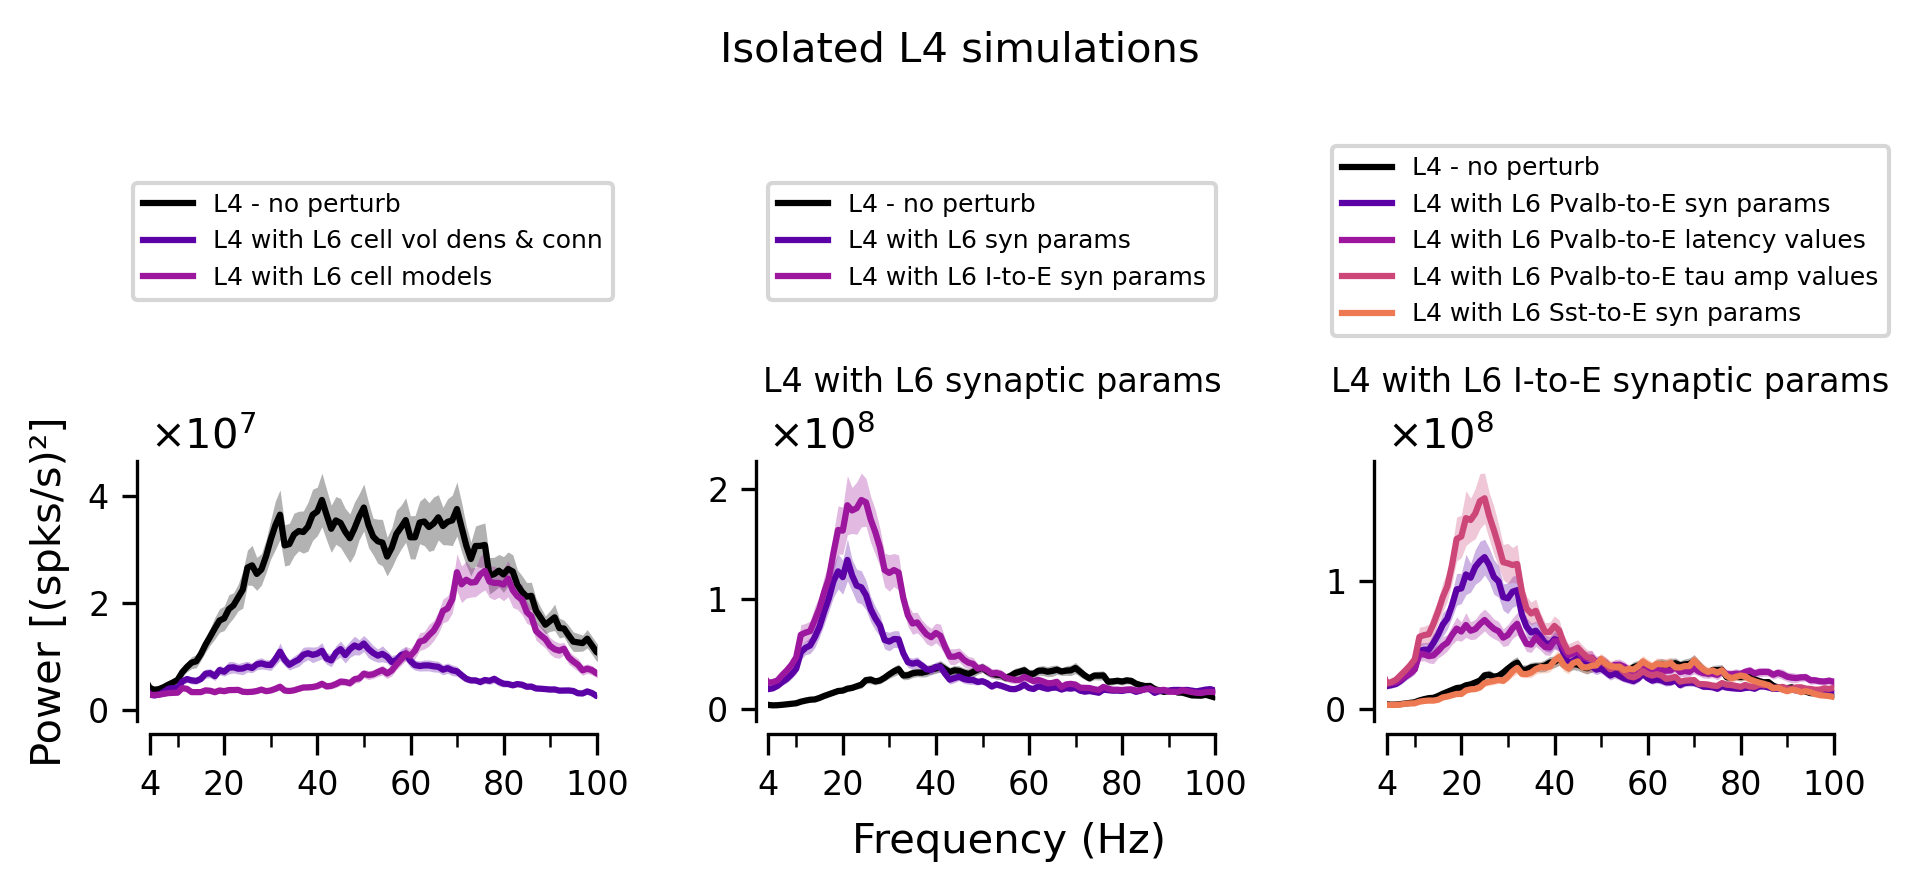

In [22]:
fig, axs = plt.subplots(2, 3, figsize=(6.5, 3), dpi=300, 
                        sharex=True, gridspec_kw={'height_ratios': [0.1, 1], 'width_ratios': [1, 1, 1]})

# axs = axs_array.flatten(), sharey=True

# colors = plt.colormaps["Set1"](np.linspace(0, 1, 9))
colors = np.delete(plt.colormaps["plasma"](np.linspace(0, 1, 7)), 6, axis=0) # 

data_noperturb = np.vstack(np.asanyarray(power_orig_net_df.loc[power_orig_net_df["condition"].isin(['no perturb']), "mean"]))

jj = 0
axes = axs[1, jj]
ii = 0
plot_func2(
    axes,
    power_orig_net_df,
    "L4",
    "L4 - no perturb",
    "k"
)
ii += 1
plot_func2(
    axes,
    power_L4_w_L6_cell_vol_dens_conn_df,
    "L4",
    "L4 with L6 cell vol dens & conn",
    colors[ii]
)
ii+=1
plot_func2(
    axes,
    power_orig_net_df,
    "L6 models: L4",
    "L4 with L6 cell models",
    colors[ii]
)
axes.set_ylabel("Power [(spks/s)²]", fontsize=10)
# axes.legend(loc="upper right", fontsize=6)
legend_ax = axs[0, jj]
legend_ax.legend(
    handles=axs[1, jj].get_legend_handles_labels()[0],
    labels=axs[1, jj].get_legend_handles_labels()[1],
    loc="center",
    bbox_to_anchor=(0.5, 0.5),
    mode=None,
    borderaxespad=0.0,
    fontsize=6,
)
# axs[0, jj].set_title("Isolated layers", fontsize=10)
axs[0, jj].get_xaxis().set_visible(False)
axs[0, jj].get_yaxis().set_visible(False)
axs[0, jj].set_axis_off()

jj += 1
ii = 0
axes = axs[1, jj]
plot_func2(
    axes,
    power_orig_net_df,
    "L4",
    "L4 - no perturb",
    "k"
)
ii += 1
plot_func2(
    axes,
    power_L4_w_L6_syn_df,
    "L4",
    "L4 with L6 syn params",
    colors[ii]
)
# plot_func2(
#     axes,    
#     power_L4_e2e_syn_as_L6_df,
#     "L4",
#     "e2e",
#     colors[ii]
# )
# ii += 1
# plot_func2(
#     axes,
#     power_L4_e2i_syn_as_L6_df,
#     "L4",
#     "e2i",
#     colors[ii]
# )
ii += 1
plot_func2(
    axes,    
    power_L4_i2e_syn_as_L6_df,
    "L4",
    "L4 with L6 I-to-E syn params",
    colors[ii]
)
axes.set_title("L4 with L6 synaptic params", fontsize=8)
# axes.set_xlabel("Frequency (Hz)", fontsize=10)
# axes.legend(loc="upper right", fontsize=6)
legend_ax = axs[0, jj]
legend_ax.legend(
    handles=axs[1, jj].get_legend_handles_labels()[0],
    labels=axs[1, jj].get_legend_handles_labels()[1],
    loc="center",
    bbox_to_anchor=(0.5, 0.5),
    mode=None,
    borderaxespad=0.0,
    fontsize=6,
)
# axs[0, jj].set_title("Isolated layers", fontsize=10)
axs[0, jj].get_xaxis().set_visible(False)
axs[0, jj].get_yaxis().set_visible(False)
axs[0, jj].set_axis_off()

jj += 1
ii = 0
axes = axs[1, jj]
plot_func2(
    axes,
    power_orig_net_df,
    "L4",
    "L4 - no perturb",
    "k"
)
ii += 1
plot_func2(
    axes,    
    power_L4_Pvalb2e_syn_as_L6_df,
    "L4",
    "L4 with L6 Pvalb-to-E syn params",
    colors[ii]
)
ii += 1
plot_func2(
    axes,    
    power_L4_Pvalb2e_syn_lat_as_L6_df,
    "L4",
    "L4 with L6 Pvalb-to-E latency values",
    colors[ii]
)
ii += 1
plot_func2(
    axes,    
    power_L4_Pvalb2e_syn_tau_amp_as_L6_df,
    "L4",
    "L4 with L6 Pvalb-to-E tau amp values",
    colors[ii]
)
ii += 1
plot_func2(
    axes,    
    power_L4_Sst2e_syn_as_L6_df,
    "L4",
    "L4 with L6 Sst-to-E syn params",
    colors[ii]
)
axes.set_title("L4 with L6 I-to-E synaptic params", fontsize=8)
# axes.legend(loc="upper right", fontsize=6)
legend_ax = axs[0, jj]
legend_ax.legend(
    handles=axs[1, jj].get_legend_handles_labels()[0],
    labels=axs[1, jj].get_legend_handles_labels()[1],
    loc="center",
    bbox_to_anchor=(0.5, 0.5),
    mode=None,
    borderaxespad=0.0,
    fontsize=6,
)
# axs[0, jj].set_title("Isolated layers", fontsize=10)
axs[0, jj].get_xaxis().set_visible(False)
axs[0, jj].get_yaxis().set_visible(False)
axs[0, jj].set_axis_off()



# fig.supylabel("Power\n[(spks/s)²]", ha='center', va='center', x=0.05, fontsize=10)
fig.supxlabel("Frequency (Hz)", ha='center', va='center', y=0.1, x=0.525, fontsize=10)
fig.suptitle("Isolated L4 simulations", ha='center', va='center', fontsize=10)
fig.tight_layout()
fig.savefig(
    "paper_figs/fig5_dg_L4sim_power_with_L6_params_Jul27_2026.pdf",
    dpi=300,
    bbox_inches="tight",
    transparent=True,
)

## Fig 5B

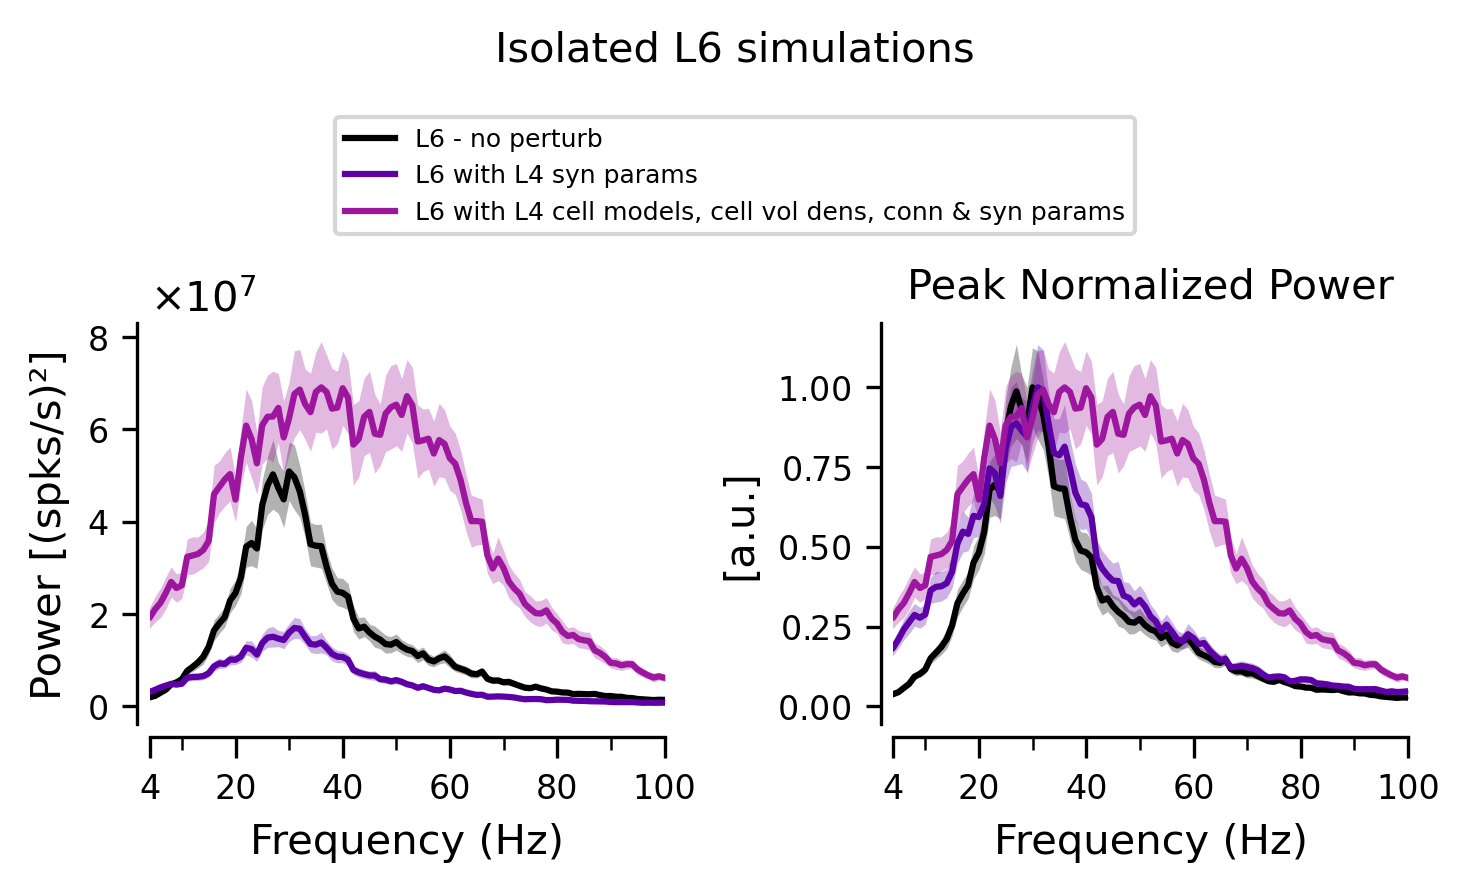

In [23]:
fig, axs = plt.subplots(2, 2, figsize=(5, 3.25), dpi=300, sharex=True, 
                        gridspec_kw={'height_ratios': [0.4, 1], 'width_ratios': [1, 1]}) # , sharey=True

# axs = axs_array.flatten()

# colors = plt.colormaps["Set1"](np.linspace(0, 1, 9))
colors = np.delete(plt.colormaps["plasma"](np.linspace(0, 1, 7)), 6, axis=0) # 

data_noperturb = np.vstack(np.asanyarray(power_orig_net_df.loc[power_orig_net_df["condition"].isin(['no perturb']), "mean"]))

jj = 0
ii = 0
axes = axs[1, jj]
plot_func2(
    axes,
    power_orig_net_df,
    "L6",
    "L6 - no perturb",
    "k",
    layer="L6"
)
ii += 1
plot_func2(
    axes,
    power_L6_w_L4_syn_df,
    "L6",
    "L6 with L4 syn params",
    colors[ii],
    layer="L6"
)
# ii += 1
# plot_func2(
#     axes,
#     power_L6_w_L4_syn_df,
#     "lgn2L6 factor 20 + L6",
#     "L6 with L4 syn params - 20 * lgn2L6 weights",
#     colors[ii],
#     layer="L6"
# )
ii += 1
plot_func2(
    axes,
    power_L6_as_L4_df,
    "L4 models: L6",
    "L6 with L4 cell models,\ncell vol dens,\nconn & syn params",
    colors[ii],
    layer="L6"
)
# ii += 1
# plot_func2(
#     axes,
#     power_L6_as_L4_df,
#     "L4 models lgn2L6 factor 2 + L6",
#     "L6 with L4 cell models,\ncell vol dens, conn & syn params - lgn2L6 factor 2",
#     colors[ii],
#     layer="L6"
# )
# ii += 1
# plot_func2(
#     axes,
#     power_L6_as_L4_df,
#     "L4 models lgn2L6 factor 5 + L6",
#     "L6 - lgn2L6 factor 5",
#     colors[ii],
#     layer="L6"
# )
# ii += 1
# plot_func2(
#     axes,
#     power_L6_as_L4_df,
#     "L4 models lgn2L6 factor 10 + L6",
#     "L6 with L4 cell models, cell vol dens, conn & syn params - lgn2L6 factor 10",
#     colors[ii],
#     layer="L6"
# )
axes.set_ylabel("Power [(spks/s)²]", fontsize=10)
# axes.set_ylabel("[(spks/s)²]", fontsize=10)
# axes.legend(loc="upper right", fontsize=6)
axes.set_xlabel("Frequency (Hz)", fontsize=10)

jj += 1
ii = 0
axes = axs[1, jj]
plot_func3(
    axes,
    power_orig_net_df,
    "L6",
    "L6 - no perturb",
    "k",
    layer="L6"
)
ii += 1
plot_func3(
    axes,
    power_L6_w_L4_syn_df,
    "L6",
    "L6 with L4 syn params",
    colors[ii],
    layer="L6"
)
# ii += 1
# plot_func3(
#     axes,
#     power_L6_w_L4_syn_df,
#     "lgn2L6 factor 20 + L6",
#     "L6 with L4 syn params - 20 * lgn2L6 weights",
#     colors[ii],
#     layer="L6"
# )
ii += 1
plot_func3(
    axes,
    power_L6_as_L4_df,
    "L4 models: L6",
    "L6 with L4 cell models, cell vol dens, conn & syn params",
    colors[ii],
    layer="L6"
)
# ii += 1
# plot_func3(
#     axes,
#     power_L6_as_L4_df,
#     "L4 models lgn2L6 factor 2 + L6",
#     "L6 with L4 cell models, cell vol dens, conn & syn params - lgn2L6 factor 2",
#     colors[ii],
#     layer="L6"
# )
# ii += 1
# plot_func3(
#     axes,
#     power_L6_as_L4_df,
#     "L4 models lgn2L6 factor 5 + L6",
#     "L6 with L4 cell models, cell vol dens, conn & syn params - lgn2L6 factor 5",
#     colors[ii],
#     layer="L6"
# )
# ii += 1
# plot_func3(
#     axes,
#     power_L6_as_L4_df,
#     "L4 models lgn2L6 factor 10 + L6",
#     "L6 with L4 cell models, cell vol dens, conn & syn params - lgn2L6 factor 10",
#     colors[ii],
#     layer="L6"
# )
axes.set_title("Peak Normalized Power", fontsize=10)
axes.set_ylabel("[a.u.]", fontsize=10)
# axes.legend(loc="lower center", fontsize="xx-small")
axes.set_xlabel("Frequency (Hz)", fontsize=10)

# # Place legend in the row above (index ii-1, since L2/3 is at ii=0 for layers[1:])
# legend_ax = axs[0, 0]  # First row for this column
# legend_ax.legend(
#     handles=axs[1, jj].get_legend_handles_labels()[0],
#     labels=axs[1, jj].get_legend_handles_labels()[1],
#     # loc="center",
#     bbox_to_anchor=(0.5, 0.5),
#     mode=None,
#     borderaxespad=0.0,
#     fontsize=6,
# )
# Hide first row axis
axs[0, 0].get_xaxis().set_visible(False)
axs[0, 0].get_yaxis().set_visible(False)
axs[0, 0].set_axis_off()
axs[0, 1].get_xaxis().set_visible(False)
axs[0, 1].get_yaxis().set_visible(False)
axs[0, 1].set_axis_off()

fig.legend(
    handles=axs[1, 1].get_legend_handles_labels()[0],
    labels=axs[1, 1].get_legend_handles_labels()[1],
    loc="center",
    bbox_to_anchor=(0.5, 0.75),  # 0.5 = horizontal center, ~0.85 = top area in figure coords
    bbox_transform=fig.transFigure,
    fontsize=6,
)

fig.suptitle("Isolated L6 simulations", fontsize=10, y = 0.9)
# fig.supylabel("Power\n[(spks/s)²]", ha='center', va='center', x=0.05)
# fig.supxlabel("Frequency (Hz)", ha='center', va='center', y=0.1)
fig.tight_layout()
fig.savefig(
    "paper_figs/fig5B_dg_L6sim_power_with_L4_params_Jul27_2026.pdf",
    dpi=300,
    bbox_inches="tight",
    transparent=True,
)

In [24]:
power_L6_as_L4_df.condition.unique()

array(['L4 models', 'L4 models: L6', 'L6', 'no perturb'], dtype=object)

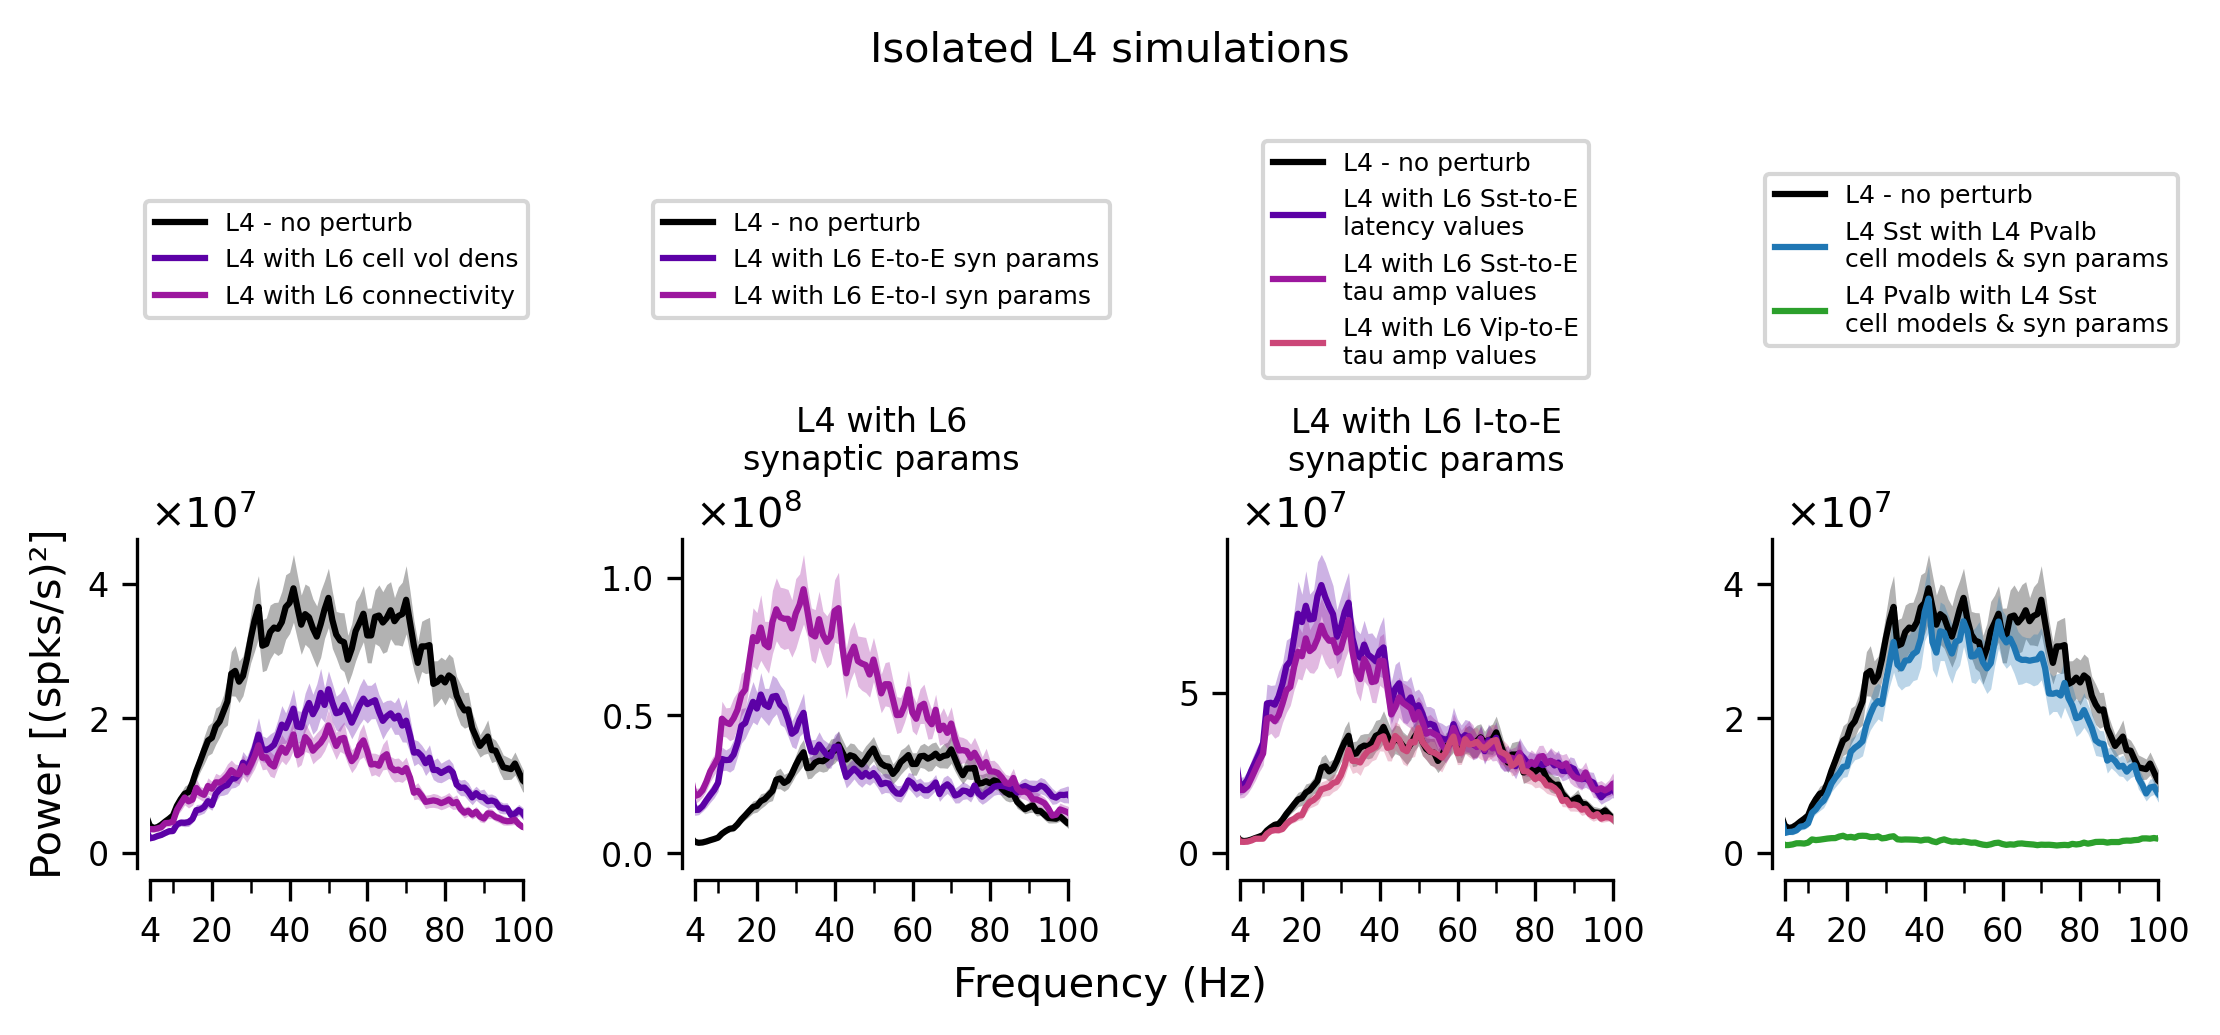

In [25]:
fig, axs = plt.subplots(2, 4, figsize=(7.5, 3.5), dpi=300, sharex=True, gridspec_kw={'height_ratios': [0.1, 1], 'width_ratios': [1, 1, 1, 1]})

# axs = axs_array.flatten()

# colors = plt.colormaps["Set1"](np.linspace(0, 1, 9))
colors = np.delete(plt.colormaps["plasma"](np.linspace(0, 1, 7)), 6, axis=0) # 

jj = 0
axes = axs[1, jj]
ii = 0
plot_func2(
    axes,
    power_orig_net_df,
    "L4",
    "L4 - no perturb",
    "k"
)
ii += 1
plot_func2(
    axes,
    power_L4_w_L6_cell_vol_dens_df,
    "L4",
    "L4 with L6 cell vol dens",
    colors[ii]
)
ii += 1
plot_func2(
    axes,
    power_L4_w_L6_conn_df,
    "L4",
    "L4 with L6 connectivity",
    colors[ii]
)
axes.set_ylabel("Power [(spks/s)²]", fontsize=10)
# axes.legend(loc="lower center", fontsize=6)
legend_ax = axs[0, jj]
legend_ax.legend(
    handles=axs[1, jj].get_legend_handles_labels()[0],
    labels=axs[1, jj].get_legend_handles_labels()[1],
    loc="center",
    bbox_to_anchor=(0.5, 0.5),
    mode=None,
    borderaxespad=0.0,
    fontsize=6,
)
# axs[0, jj].set_title("Isolated layers", fontsize=10)
axs[0, jj].get_xaxis().set_visible(False)
axs[0, jj].get_yaxis().set_visible(False)
axs[0, jj].set_axis_off()

jj += 1
ii = 0
axes = axs[1, jj]
plot_func2(
    axes,
    power_orig_net_df,
    "L4",
     "L4 - no perturb",
    "k"
)
ii += 1
plot_func2(
    axes,    
    power_L4_e2e_syn_as_L6_df,
    "L4",
    "L4 with L6 E-to-E syn params",
    colors[ii]
)
ii += 1
plot_func2(
    axes,
    power_L4_e2i_syn_as_L6_df,
    "L4",
    "L4 with L6 E-to-I syn params",
    colors[ii]
)
axes.set_title("L4 with L6\nsynaptic params", fontsize=8)
# axes.set_xlabel("Frequency (Hz)", fontsize=10)
# axes.legend(loc="upper right", fontsize=6)
legend_ax = axs[0, jj]
legend_ax.legend(
    handles=axs[1, jj].get_legend_handles_labels()[0],
    labels=axs[1, jj].get_legend_handles_labels()[1],
    loc="center",
    bbox_to_anchor=(0.5, 0.5),
    mode=None,
    borderaxespad=0.0,
    fontsize=6,
)
# axs[0, jj].set_title("Isolated layers", fontsize=10)
axs[0, jj].get_xaxis().set_visible(False)
axs[0, jj].get_yaxis().set_visible(False)
axs[0, jj].set_axis_off()

jj += 1
ii = 0
axes = axs[1, jj]
plot_func2(
    axes,
    power_orig_net_df,
    "L4",
    "L4 - no perturb",
    "k"
)
ii += 1
plot_func2(
    axes,    
    power_L4_Sst2e_syn_lat_as_L6_df,
    "L4",
    "L4 with L6 Sst-to-E\nlatency values",
    colors[ii]
)
ii += 1
plot_func2(
    axes,    
    power_L4_Sst2e_syn_tau_amp_as_L6_df,
    "L4",
    "L4 with L6 Sst-to-E\ntau amp values",
    colors[ii]
)
# ii += 1
# plot_func2(
#     axes,    
#     power_L4_Vip2e_syn_lat_as_L6_df,
#     "L4",
#     "L4 with L6 Vip-to-E\nlatency values",
#     colors[ii]
# )
ii += 1
plot_func2(
    axes,    
    power_L4_Vip2e_syn_tau_amp_as_L6_df,
    "L4",
    "L4 with L6 Vip-to-E\ntau amp values",
    colors[ii]
)   
axes.set_title("L4 with L6 I-to-E\nsynaptic params", fontsize=8)
legend_ax = axs[0, jj]
legend_ax.legend(
    handles=axs[1, jj].get_legend_handles_labels()[0],
    labels=axs[1, jj].get_legend_handles_labels()[1],
    loc="center",
    bbox_to_anchor=(0.5, 0.5),
    mode=None,
    borderaxespad=0.0,
    fontsize=6,
)
# axs[0, jj].set_title("Isolated layers", fontsize=10)
axs[0, jj].get_xaxis().set_visible(False)
axs[0, jj].get_yaxis().set_visible(False)
axs[0, jj].set_axis_off()


colors = ["tab:blue", "tab:green"]
ii = 0
jj += 1
axes = axs[1, jj]
plot_func2(
    axes,
    power_orig_net_df,
    "L4",
    "L4 - no perturb",
    "k"
)
plot_func2(
    axes,
    power_i4Sst_like_i4Pvalb_df,
    "L4",
    "L4 Sst with L4 Pvalb\ncell models & syn params",
    colors[ii]
)
ii += 1
plot_func2(
    axes,
    power_i4Pvalb_like_i4Sst_df,
    "L4",
    "L4 Pvalb with L4 Sst\ncell models & syn params",
    colors[ii]
)
legend_ax = axs[0, jj]
legend_ax.legend(
    handles=axs[1, jj].get_legend_handles_labels()[0],
    labels=axs[1, jj].get_legend_handles_labels()[1],
    loc="center",
    bbox_to_anchor=(0.5, 0.5),
    mode=None,
    borderaxespad=0.0,
    fontsize=6,
)
# axs[0, jj].set_title("Isolated layers", fontsize=10)
axs[0, jj].get_xaxis().set_visible(False)
axs[0, jj].get_yaxis().set_visible(False)
axs[0, jj].set_axis_off()

# fig.supylabel("Power [(spks/s)²]", fontsize=10)
fig.supxlabel("Frequency (Hz)", fontsize=10, y=0.07)
fig.suptitle("Isolated L4 simulations", ha='center', va='center', fontsize=10)
fig.tight_layout()
fig.savefig(
    "paper_figs/fig5A_suppl_dg_L4sim_power_spectrum_Jul27_2026.pdf",
    dpi=300,
    bbox_inches="tight",
    transparent=True,
)


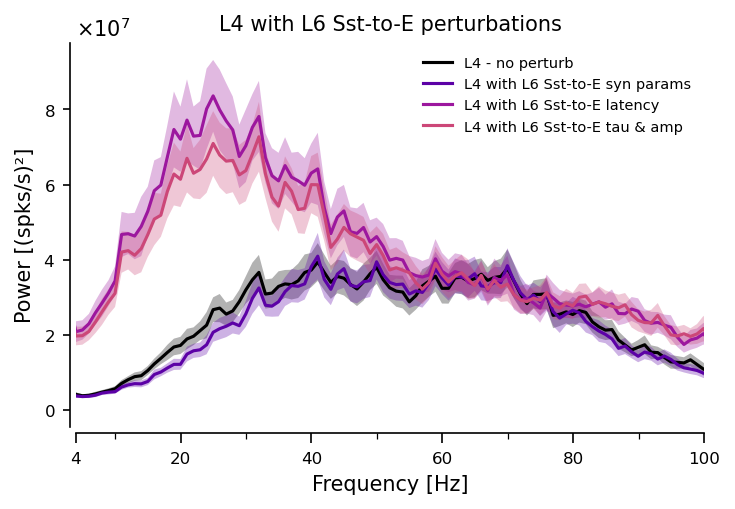

In [26]:

# ── L4 with L6 Sst-to-E perturbations — all cases ───────────────────────────────
colors_sst = np.delete(plt.colormaps["plasma"](np.linspace(0, 1, 7)), 6, axis=0)

fig_sst, ax_sst = plt.subplots(figsize=(5, 3.5), dpi=150)

plot_func2(ax_sst, power_orig_net_df,            "L4", "L4 - no perturb",                    "k")
plot_func2(ax_sst, power_L4_Sst2e_syn_as_L6_df,      "L4", "L4 with L6 Sst-to-E syn params",    colors_sst[1])
plot_func2(ax_sst, power_L4_Sst2e_syn_lat_as_L6_df,  "L4", "L4 with L6 Sst-to-E latency",       colors_sst[2])
plot_func2(ax_sst, power_L4_Sst2e_syn_tau_amp_as_L6_df, "L4", "L4 with L6 Sst-to-E tau & amp",  colors_sst[3])

ax_sst.set_xlabel("Frequency [Hz]", fontsize=10)
ax_sst.set_ylabel("Power [(spks/s)²]", fontsize=10)
ax_sst.set_title("L4 with L6 Sst-to-E perturbations", fontsize=10)
ax_sst.legend(fontsize=7, frameon=False, loc="upper right")
fig_sst.tight_layout()
plt.show()


## Synaptic parameters of the V1 model (pre → post)

Each of the parameters below is defined for every **presynaptic → postsynaptic** population pair, so each one is naturally a matrix. **Annotated heatmaps** are the clearest representation: the full pre/post structure is visible at a glance, colour encodes magnitude, and the printed value gives the exact number. The **Pvalb → Exc** connections (the `Pvalb` row across all excitatory targets) are outlined in red.

- `base_props/tau_syn_fast.csv`, `base_props/tau_syn_slow.csv` — fast and slow time constants of the double-alpha synaptic current (stored in s, shown in ms)
- `base_props/syn_types_latency.csv` — synaptic latency (ms)
- `base_props/amp_slow.csv` — amplitude of the slow component of the double-alpha synaptic current (a.u.)

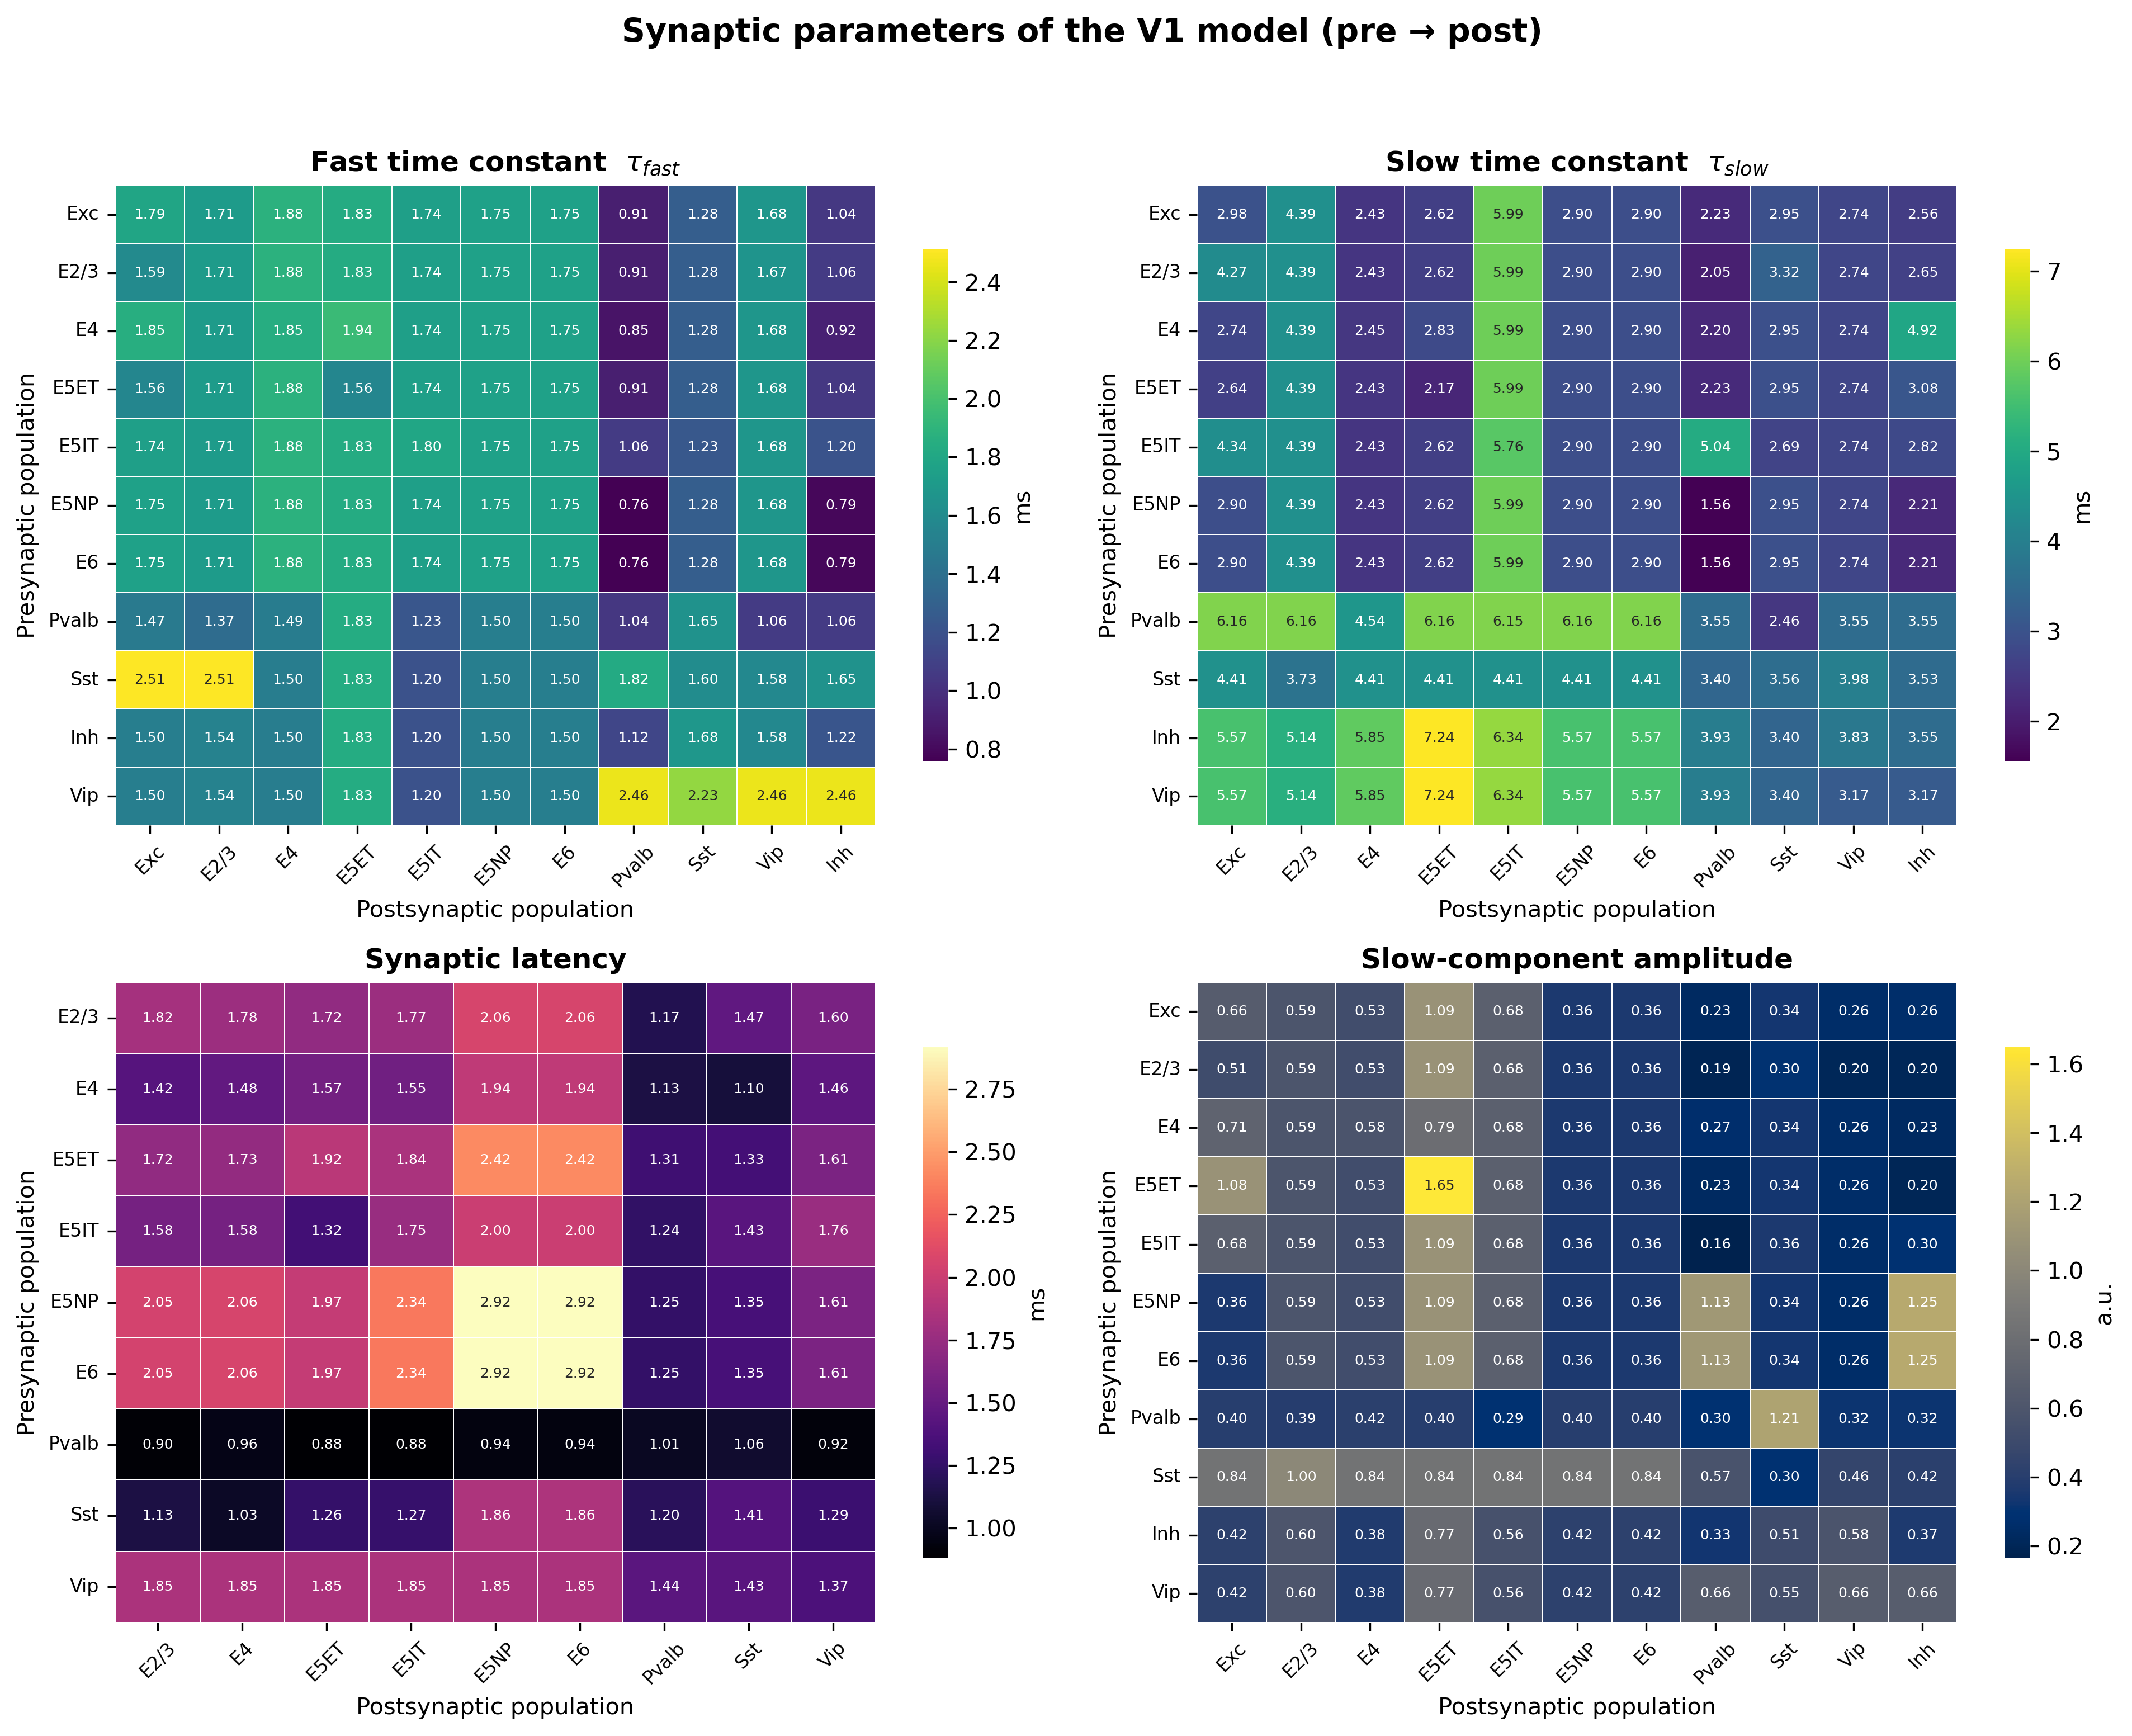

In [27]:
# ── Synaptic parameters as pre → post heatmaps, Pvalb → Exc highlighted ──────────
from matplotlib.patches import Rectangle

# rows = presynaptic population, columns = postsynaptic population
tau_fast = pd.read_csv("base_props/tau_syn_fast.csv", sep=" ", index_col=0) * 1e3  # s -> ms
tau_slow = pd.read_csv("base_props/tau_syn_slow.csv", sep=" ", index_col=0) * 1e3  # s -> ms
latency = pd.read_csv("base_props/syn_types_latency.csv", sep=" ", index_col=0)    # ms
amp_slow = pd.read_csv("base_props/amp_slow.csv", sep=" ", index_col=0)            # a.u.

# pretty display names for the population labels
LABELS = {
    "exc": "Exc", "e23": "E2/3", "e4": "E4", "e5et": "E5ET", "e5it": "E5IT",
    "e5np": "E5NP", "e6": "E6", "pv": "Pvalb", "sst": "Sst", "vip": "Vip", "inh": "Inh",
}
EXC_POPS = {"exc", "e23", "e4", "e5et", "e5it", "e5np", "e6"}


def _disp(names):
    return [LABELS.get(n, n) for n in names]


def _highlight_pvalb_to_exc(ax, df):
    """Outline the Pvalb -> excitatory block (pv row x excitatory columns)."""
    if "pv" not in df.index:
        return
    row = df.index.get_loc("pv")
    cols = sorted(df.columns.get_loc(c) for c in df.columns if c in EXC_POPS)
    # # one rectangle per contiguous run of excitatory columns
    # start = prev = cols[0]
    # for col in cols[1:] + [None]:
    #     if col != prev + 1:
    #         ax.add_patch(Rectangle((start, row), prev - start + 1, 1, fill=False,
    #                                edgecolor="red", lw=2.5, zorder=5))
    #         start = col
    #     prev = col


_panels = [
    (tau_fast, r"Fast time constant  $\tau_{fast}$", "ms", "viridis"),
    (tau_slow, r"Slow time constant  $\tau_{slow}$", "ms", "viridis"),
    (latency, "Synaptic latency", "ms", "magma"),
    (amp_slow, "Slow-component amplitude", "a.u.", "cividis"),
]

fig, axs = plt.subplots(2, 2, figsize=(13, 10), dpi=300)

for ax, (df, title, unit, cmap) in zip(axs.flat, _panels):
    sns.heatmap(
        df, ax=ax, cmap=cmap, annot=True, fmt=".2f",
        annot_kws={"fontsize": 6}, linewidths=0.4, linecolor="white",
        cbar_kws={"label": unit, "shrink": 0.8},
        xticklabels=_disp(df.columns), yticklabels=_disp(df.index),
    )
    _highlight_pvalb_to_exc(ax, df)
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("Postsynaptic population", fontsize=10)
    ax.set_ylabel("Presynaptic population", fontsize=10)
    ax.tick_params(axis="x", rotation=45, labelsize=8)
    ax.tick_params(axis="y", rotation=0, labelsize=8)

# fig.legend(
#     handles=[Rectangle((0, 0), 1, 1, fill=False, edgecolor="red", lw=2.5)],
#     labels=["Pvalb → Exc synapses"], loc="upper center",
#     frameon=False, fontsize=11, bbox_to_anchor=(0.5, 1.0),
# )
fig.suptitle("Synaptic parameters of the V1 model (pre → post)",
             fontsize=14, fontweight="bold", y=1.03)
fig.tight_layout()
fig.savefig(
    "paper_figs/fig5_suppl_syn_params_heatmaps_Jun29_2026.pdf",
    dpi=300,
    bbox_inches="tight",
    transparent=True,
)

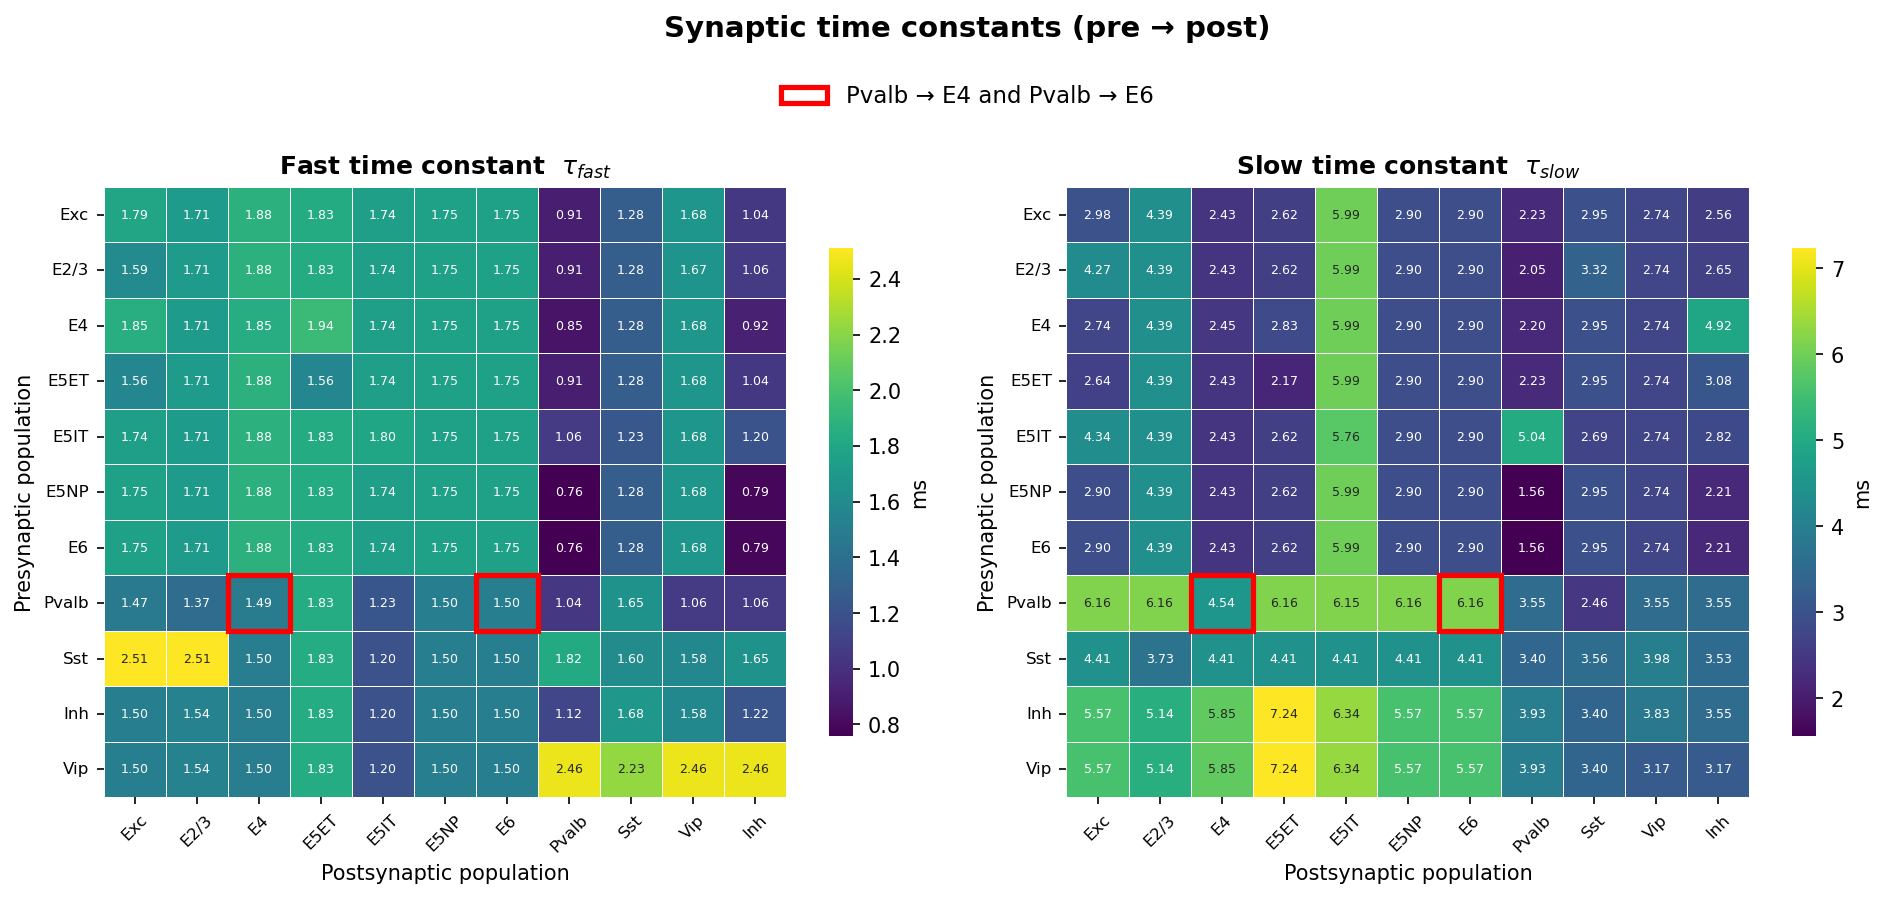

In [28]:
# ── Synaptic time constants only, Pvalb → E4 and Pvalb → E6 highlighted ──────────
from matplotlib.patches import Rectangle

tau_fast = pd.read_csv("base_props/tau_syn_fast.csv", sep=" ", index_col=0) * 1e3  # s -> ms
tau_slow = pd.read_csv("base_props/tau_syn_slow.csv", sep=" ", index_col=0) * 1e3  # s -> ms

LABELS = {
    "exc": "Exc", "e23": "E2/3", "e4": "E4", "e5et": "E5ET", "e5it": "E5IT",
    "e5np": "E5NP", "e6": "E6", "pv": "Pvalb", "sst": "Sst", "vip": "Vip", "inh": "Inh",
}
HIGHLIGHT_TARGETS = ["e4", "e6"]  # Pvalb -> E4 and Pvalb -> E6


def _disp(names):
    return [LABELS.get(n, n) for n in names]


def _highlight_pvalb_to_e4e6(ax, df):
    """Outline the Pvalb -> E4 and Pvalb -> E6 cells."""
    if "pv" not in df.index:
        return
    row = df.index.get_loc("pv")
    for tgt in HIGHLIGHT_TARGETS:
        if tgt in df.columns:
            col = df.columns.get_loc(tgt)
            ax.add_patch(Rectangle((col, row), 1, 1, fill=False,
                                   edgecolor="red", lw=2.5, zorder=5))


_tau_panels = [
    (tau_fast, r"Fast time constant  $\tau_{fast}$"),
    (tau_slow, r"Slow time constant  $\tau_{slow}$"),
]

fig, axs = plt.subplots(1, 2, figsize=(13, 5.5), dpi=150)

for ax, (df, title) in zip(axs.flat, _tau_panels):
    sns.heatmap(
        df, ax=ax, cmap="viridis", annot=True, fmt=".2f",
        annot_kws={"fontsize": 6}, linewidths=0.4, linecolor="white",
        cbar_kws={"label": "ms", "shrink": 0.8},
        xticklabels=_disp(df.columns), yticklabels=_disp(df.index),
    )
    _highlight_pvalb_to_e4e6(ax, df)
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("Postsynaptic population", fontsize=10)
    ax.set_ylabel("Presynaptic population", fontsize=10)
    ax.tick_params(axis="x", rotation=45, labelsize=8)
    ax.tick_params(axis="y", rotation=0, labelsize=8)

fig.legend(
    handles=[Rectangle((0, 0), 1, 1, fill=False, edgecolor="red", lw=2.5)],
    labels=["Pvalb → E4 and Pvalb → E6"], loc="upper center",
    frameon=False, fontsize=11, bbox_to_anchor=(0.5, 1.02),
)
fig.suptitle("Synaptic time constants (pre → post)",
             fontsize=14, fontweight="bold", y=1.08)
fig.tight_layout()
plt.show()

### Synaptic time constants — inhibitory presynaptic populations

Same time-constant heatmaps, but restricted to the inhibitory presynaptic populations (`Pvalb`, `Sst`, `Vip`, `Inh`); all postsynaptic targets are kept. The **Pvalb → E4** and **Pvalb → E6** connections are outlined in red.

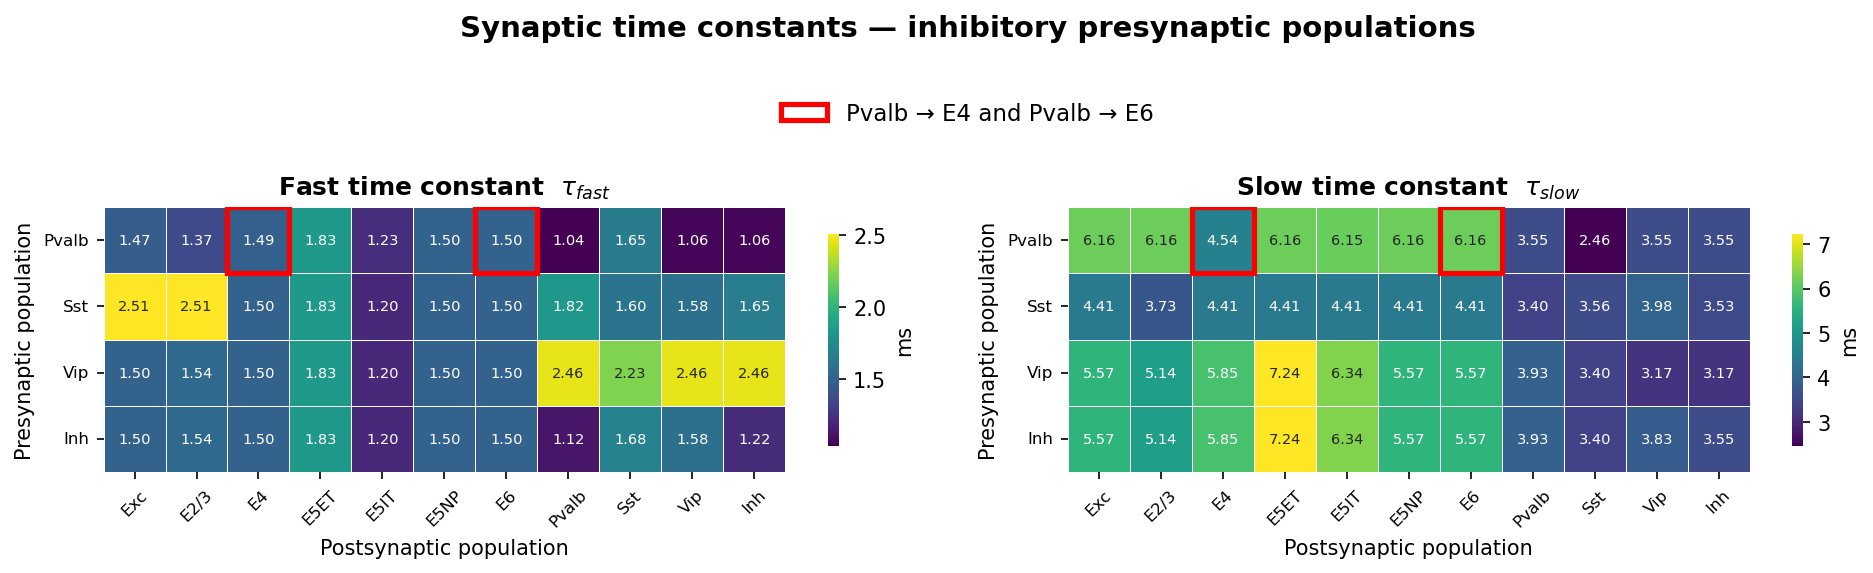

In [29]:
# ── Time constants for inhibitory presynaptic pops, Pvalb → E4/E6 highlighted ────
from matplotlib.patches import Rectangle

tau_fast = pd.read_csv("base_props/tau_syn_fast.csv", sep=" ", index_col=0) * 1e3  # s -> ms
tau_slow = pd.read_csv("base_props/tau_syn_slow.csv", sep=" ", index_col=0) * 1e3  # s -> ms

LABELS = {
    "exc": "Exc", "e23": "E2/3", "e4": "E4", "e5et": "E5ET", "e5it": "E5IT",
    "e5np": "E5NP", "e6": "E6", "pv": "Pvalb", "sst": "Sst", "vip": "Vip", "inh": "Inh",
}
PRE_KEEP = ["pv", "sst", "vip", "inh"]  # inhibitory presynaptic populations only
HIGHLIGHT_TARGETS = ["e4", "e6"]        # Pvalb -> E4 and Pvalb -> E6


def _disp(names):
    return [LABELS.get(n, n) for n in names]


def _highlight_pvalb_to_e4e6(ax, df):
    """Outline the Pvalb -> E4 and Pvalb -> E6 cells."""
    if "pv" not in df.index:
        return
    row = df.index.get_loc("pv")
    for tgt in HIGHLIGHT_TARGETS:
        if tgt in df.columns:
            col = df.columns.get_loc(tgt)
            ax.add_patch(Rectangle((col, row), 1, 1, fill=False,
                                   edgecolor="red", lw=2.5, zorder=5))


_tau_panels = [
    (tau_fast.loc[PRE_KEEP], r"Fast time constant  $\tau_{fast}$"),
    (tau_slow.loc[PRE_KEEP], r"Slow time constant  $\tau_{slow}$"),
]

fig, axs = plt.subplots(1, 2, figsize=(13, 3.2), dpi=150)

for ax, (df, title) in zip(axs.flat, _tau_panels):
    sns.heatmap(
        df, ax=ax, cmap="viridis", annot=True, fmt=".2f",
        annot_kws={"fontsize": 7}, linewidths=0.4, linecolor="white",
        cbar_kws={"label": "ms", "shrink": 0.8},
        xticklabels=_disp(df.columns), yticklabels=_disp(df.index),
    )
    _highlight_pvalb_to_e4e6(ax, df)
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("Postsynaptic population", fontsize=10)
    ax.set_ylabel("Presynaptic population", fontsize=10)
    ax.tick_params(axis="x", rotation=45, labelsize=8)
    ax.tick_params(axis="y", rotation=0, labelsize=8)

fig.legend(
    handles=[Rectangle((0, 0), 1, 1, fill=False, edgecolor="red", lw=2.5)],
    labels=["Pvalb → E4 and Pvalb → E6"], loc="upper center",
    frameon=False, fontsize=11, bbox_to_anchor=(0.5, 1.04),
)
fig.suptitle("Synaptic time constants — inhibitory presynaptic populations",
             fontsize=14, fontweight="bold", y=1.18)
fig.tight_layout()
plt.show()

### Synaptic parameters — E4, E6, Pvalb, Sst, Vip subset

Same four-panel figure as above (fast & slow time constants, latency, slow-component amplitude), but restricted to `E4, E6, Pvalb, Sst, Vip` for **both** the presynaptic (rows) and postsynaptic (columns) populations. The **Pvalb → Exc** connections (here `E4` and `E6`) are outlined in red.

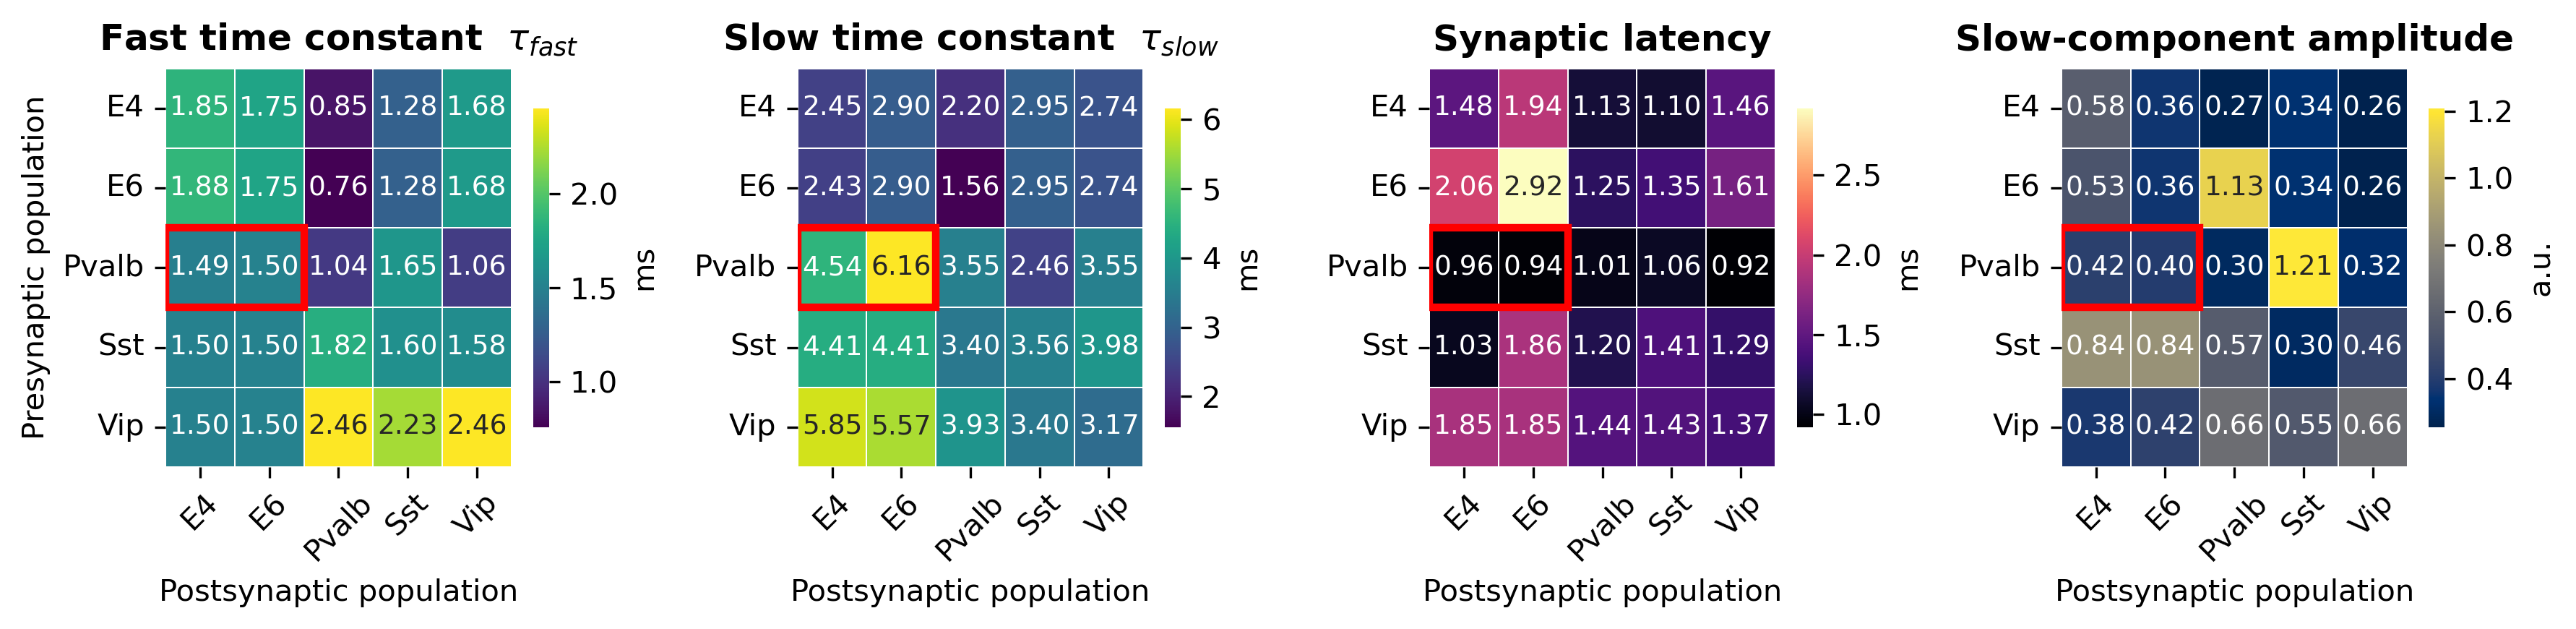

In [30]:
# ── 4-panel synaptic parameters, subset to E4/E6/Pvalb/Sst/Vip (pre & post) ──────
from matplotlib.patches import Rectangle

tau_fast = pd.read_csv("base_props/tau_syn_fast.csv", sep=" ", index_col=0) * 1e3  # s -> ms
tau_slow = pd.read_csv("base_props/tau_syn_slow.csv", sep=" ", index_col=0) * 1e3  # s -> ms
latency = pd.read_csv("base_props/syn_types_latency.csv", sep=" ", index_col=0)    # ms
amp_slow = pd.read_csv("base_props/amp_slow.csv", sep=" ", index_col=0)            # a.u.

LABELS = {
    "exc": "Exc", "e23": "E2/3", "e4": "E4", "e5et": "E5ET", "e5it": "E5IT",
    "e5np": "E5NP", "e6": "E6", "pv": "Pvalb", "sst": "Sst", "vip": "Vip", "inh": "Inh",
}
POPS = ["e4", "e6", "pv", "sst", "vip"]  # subset shown for both pre (rows) and post (cols)
EXC_POPS = {"exc", "e23", "e4", "e5et", "e5it", "e5np", "e6"}


def _disp(names):
    return [LABELS.get(n, n) for n in names]


def _sub(df):
    return df.loc[POPS, POPS]


def _highlight_pvalb_to_exc(ax, df):
    """Outline the Pvalb -> excitatory block (pv row x excitatory columns)."""
    if "pv" not in df.index:
        return
    row = df.index.get_loc("pv")
    cols = sorted(df.columns.get_loc(c) for c in df.columns if c in EXC_POPS)
    if not cols:
        return
    # one rectangle per contiguous run of excitatory columns
    start = prev = cols[0]
    for col in cols[1:] + [None]:
        if col != prev + 1:
            ax.add_patch(Rectangle((start, row), prev - start + 1, 1, fill=False,
                                   edgecolor="red", lw=2.5, zorder=5))
            start = col
        prev = col


_panels = [
    (_sub(tau_fast), r"Fast time constant  $\tau_{fast}$", "ms", "viridis"),
    (_sub(tau_slow), r"Slow time constant  $\tau_{slow}$", "ms", "viridis"),
    (_sub(latency), "Synaptic latency", "ms", "magma"),
    (_sub(amp_slow), "Slow-component amplitude", "a.u.", "cividis"),
]

fig, axs = plt.subplots(1, 4, figsize=(12, 3), dpi=300)

for ax, (df, title, unit, cmap) in zip(axs.flat, _panels):
    sns.heatmap(
        df, ax=ax, cmap=cmap, annot=True, fmt=".2f",
        annot_kws={"fontsize": 9}, linewidths=0.4, linecolor="white",
        cbar_kws={"label": unit, "shrink": 0.8},
        xticklabels=_disp(df.columns), yticklabels=_disp(df.index),
    )
    _highlight_pvalb_to_exc(ax, df)
    ax.set_title(title, fontsize=12, fontweight="bold")
    if df is _panels[0][0]:  # first panel
        ax.set_ylabel("Presynaptic population", fontsize=10)
    else:
        ax.set_ylabel("")
    ax.set_xlabel("Postsynaptic population", fontsize=10)
    ax.tick_params(axis="x", rotation=45, labelsize=10)
    ax.tick_params(axis="y", rotation=0, labelsize=10)

# fig.legend(
#     handles=[Rectangle((0, 0), 1, 1, fill=False, edgecolor="red", lw=2.5)],
#     labels=["Pvalb → Exc synapses"], loc="upper center",
#     frameon=False, fontsize=11, bbox_to_anchor=(0.5, 1.0),
# )
# fig.suptitle("Synaptic parameters (pre → post) — E4, E6, Pvalb, Sst, Vip",
#              fontsize=14, fontweight="bold", y=1.03)
fig.tight_layout()
fig.savefig(
    "paper_figs/fig5B_syn_params_heatmaps_E4E6PvalbSstVip_Jun23_2026.pdf",
    dpi=300,
    bbox_inches="tight",
    transparent=True,
)
plt.show()